In [1]:
# ============================================================
# Identificadores del grupo. Su suma determina la semilla y los parámetros de la simulación.
# ============================================================
C1 = 1141318021   # cédula / código del integrante 1
C2 = 1018421230   # cédula / código del integrante 2 (Juan Sebastián García)
S = (C1 + C2) if (C1 is not None and C2 is not None) else None

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 90)

# Rutas de búsqueda de los CSV: carpeta actual, directorio superior y /content.
CANDIDATAS = [Path("."), Path(".."), Path("/content")]
RUTA_DATOS = next(p for p in CANDIDATAS if (p / "solicitudes.csv").exists())
RUTA_SALIDA = Path(".")
print("Datos leídos de:", RUTA_DATOS.resolve())

rng = np.random.default_rng(S)

Datos leídos de: C:\Users\jpabl\.orca\bots\omi\cci-task_cd106359c538\revision


# Proyecto Final CCI · AndesVision

Ejecutar A–G en orden en la carpeta de los tres CSV. F6 es el único acceso a la ventana de validación.

In [2]:
# Lectura de la telemetría original, previa a los filtros de calidad.
# La tabla cruda sirve de referencia para cuantificar los cambios de la limpieza.
crudo = pd.read_csv(RUTA_DATOS / "solicitudes.csv")
print("Filas:", len(crudo), "| Columnas:", list(crudo.columns))
crudo.describe().T.round(3)

Filas: 32603 | Columnas: ['id_solicitud', 't_llegada_s', 'tam_kb', 'cache_hit', 'version', 'red_ms', 'gpu_ms', 'latencia_ms', 'intentos', 'exito']


,count,mean,std,min,25%,50%,75%,max
id_solicitud,32603.0,16250.945,9383.383,1.000,8127.500,16249.00,24374.500,32506.000
t_llegada_s,32603.0,601.331,312.229,0.018,370.488,605.31,823.112,1199.956
tam_kb,32603.0,632.456,12190.291,1.290,114.770,201.65,325.345,858112.000
cache_hit,32603.0,0.317,0.465,0.000,0.000,0.00,1.000,1.000
red_ms,32570.0,23.365,3.581,8.290,20.960,23.33,25.800,38.390
gpu_ms,32571.0,31.557,34.712,0.000,0.000,24.70,47.415,392.690
latencia_ms,32603.0,67.907,54.797,-1.000,26.020,53.77,87.725,625.590
intentos,32603.0,1.235,0.513,1.000,1.000,1.00,1.000,3.000
exito,32603.0,0.990,0.099,0.000,1.000,1.00,1.000,1.000


## A1. Auditoría de `solicitudes.csv`

Cada regla sale de cómo funciona el sistema real (sección 4.1 del enunciado):

| Regla física | Por qué |
|---|---|
| Cada `id_solicitud` es único | Una solicitud se registra una vez |
| Los tiempos entre llegadas son ≥ 0 | El tiempo no retrocede |
| `red_ms` > 0 y `tam_kb` en un rango posible | Tiempos y tamaños no pueden ser negativos ni absurdos |
| Si `cache_hit = 1`, entonces `gpu_ms = 0` | Una respuesta de caché no usa GPU |
| `latencia_ms` ≥ `red_ms` + `gpu_ms` | Porque L = red + espera + G y la espera en cola es ≥ 0 |
| Si `exito = 0`, entonces `intentos = 3` | El SDK solo abandona tras 3 intentos fallidos |

In [3]:
TOL = 0.021  # suma de tiempos redondeados a centésimas
# Cada bandera identifica una regla incumplida. Una fila puede activar varias reglas a la vez.
def detectar_inconsistencias(d):
    # Se comprueba si el tamaño convertido a KB cae en rango y tiene precisión de centésimas.
    tam_convertido_kb = d.tam_kb / 1024
    centesimas_kb = tam_convertido_kb * 100
    en_rango = tam_convertido_kb.between(1, 2000)
    en_centesimas = np.isclose(centesimas_kb, np.rint(centesimas_kb), atol=1e-6, rtol=0)
    escala = (d.tam_kb > 10000) & en_rango & en_centesimas

    duplicada = d.duplicated()
    ids_sin_copias = d.loc[~duplicada, "id_solicitud"]
    id_repetido = ids_sin_copias.duplicated(keep=False).reindex(d.index, fill_value=False)
    cache_con_gpu = (d.cache_hit == 1) & (d.gpu_ms > 0)
    # Se resta la red y el tiempo de GPU de la latencia, todo en ms.
    resto_ms = d.latencia_ms - d.red_ms.abs() - d.gpu_ms
    latencia_imposible = (d.latencia_ms < 0) | ((resto_ms < -TOL) & ~cache_con_gpu)
    return pd.DataFrame({
        "duplicada": duplicada,
        "id_repetido_no_exacto": ~duplicada & id_repetido,
        "tam_escala": escala, "tam_vacio": d.tam_kb.isna(),
        "red_faltante": d.red_ms.isna(), "gpu_faltante": d.gpu_ms.isna(),
        "red_negativa": d.red_ms < 0,
        "cache_con_gpu": cache_con_gpu,
        "latencia_imposible": latencia_imposible,
        "exito_sin_3_intentos": (d.exito == 0) & (d.intentos < 3),
    })

banderas = detectar_inconsistencias(crudo)
sin_dup = crudo[~banderas.duplicada]
saltos_atras = int((sin_dup.t_llegada_s.diff() < 0).sum())
print(banderas.sum().to_string())
print("Saltos temporales:", saltos_atras)

duplicada                 96
id_repetido_no_exacto      2
tam_escala                48
tam_vacio                  0
red_faltante              33
gpu_faltante              32
red_negativa               0
cache_con_gpu              0
latencia_imposible       162
exito_sin_3_intentos       0
Saltos temporales: 0


### Evidencia cuantitativa de cada decisión

In [4]:
# Evidencia de doble escala y del duplicado con una medición contradictoria.
tam_alt = crudo.loc[banderas.tam_escala, "tam_kb"]
print("Tamaño sin cambio de escala, máximo (KB):", crudo.loc[~banderas.tam_escala,"tam_kb"].max())
print("Rango tras corregir por 1024 (KB):", (tam_alt/1024).agg(["min","max"]).to_dict())
print("Resolución máxima del tamaño corregido respecto a centésimas:",
      np.max(np.abs(tam_alt/1024*100-np.rint(tam_alt/1024*100))))
print("Latencias de ID repetido no exacto:", crudo.loc[banderas.id_repetido_no_exacto,"latencia_ms"].tolist())
print("Frecuencias de latencia imposible:", crudo.loc[banderas.latencia_imposible,"latencia_ms"].value_counts().head().to_dict())
print(pd.crosstab(crudo.intentos, crudo.exito))

Tamaño sin cambio de escala, máximo (KB): 1610.44
Rango tras corregir por 1024 (KB): {'min': 26.39, 'max': 838.0}
Resolución máxima del tamaño corregido respecto a centésimas: 7.275957614183426e-12
Latencias de ID repetido no exacto: [-1.0, 203.14]
Frecuencias de latencia imposible: {-1.0: 97, 37.48: 1, 16.58: 1, 15.37: 1, 37.65: 1}
exito       0      1
intentos            
1           0  26314
2           0   4931
3         323   1035


In [5]:
# Una solicitud real sigue contando como llegada aunque falte una de sus mediciones.
def limpiar(d, corregir_escala=True):
    b = detectar_inconsistencias(d)
    out = d.loc[~b.duplicada].copy()
    b = b.loc[out.index]
    out["red_ms"] = out["red_ms"].abs()
    out.loc[b.tam_escala, "tam_kb"] = out.loc[b.tam_escala, "tam_kb"] / 1024 if corregir_escala else np.nan
    out.loc[b.cache_con_gpu, ["cache_hit", "gpu_ms"]] = np.nan
    out.loc[b.latencia_imposible, "latencia_ms"] = np.nan
    out.loc[b.exito_sin_3_intentos, ["intentos", "exito"]] = np.nan
    # Para cada identificador en conflicto se conserva la fila con más mediciones válidas.
    out = (out.assign(_validos=out.notna().sum(axis=1)).sort_values("_validos", ascending=False, kind="stable")
          .drop_duplicates("id_solicitud").drop(columns="_validos")
          .sort_values("t_llegada_s", kind="stable").reset_index(drop=True))
    return out

df = limpiar(crudo)
print("Solicitudes únicas:", len(df))
comparacion_tam = {}
for etiqueta, datos in {"corregido":df, "tamaños dudosos omitidos":limpiar(crudo, False)}.items():
    muestra = datos.loc[datos.cache_hit.eq(0), ["tam_kb","gpu_ms"]].dropna()
    comparacion_tam[etiqueta] = muestra.corr().loc["tam_kb","gpu_ms"]
print("Sensibilidad de Pearson a la política de tamaños:", comparacion_tam)

Solicitudes únicas: 32506
Sensibilidad de Pearson a la política de tamaños: {'corregido': np.float64(0.6324664731969034), 'tamaños dudosos omitidos': np.float64(0.6323165420225075)}


In [6]:
politicas = {
"duplicada":"Quitar copia exacta", "id_repetido_no_exacto":"Conservar la medición físicamente válida",
"tam_escala":"Dividir por 1024, patrón de centésimas reconstruido", "tam_vacio":"Excluir por variable",
"red_faltante":"Excluir solo de análisis de red", "gpu_faltante":"Excluir solo de análisis de GPU",
"red_negativa":"Corregir signo", "cache_con_gpu":"Invalidar caché y GPU",
"latencia_imposible":"Invalidar latencia", "exito_sin_3_intentos":"Invalidar intentos y éxito"}
tabla_A1 = pd.DataFrame({"filas":banderas.sum(), "tratamiento":pd.Series(politicas)})
tabla_A1.loc["saltos hacia atrás"] = [saltos_atras, "Ordenar por tiempo"]
display(tabla_A1)

,filas,tratamiento
duplicada,96,Quitar copia exacta
id_repetido_no_exacto,2,Conservar la medición físicamente válida
tam_escala,48,"Dividir por 1024, patrón de centésimas reconstruido"
tam_vacio,0,Excluir por variable
red_faltante,33,Excluir solo de análisis de red
gpu_faltante,32,Excluir solo de análisis de GPU
red_negativa,0,Corregir signo
cache_con_gpu,0,Invalidar caché y GPU
latencia_imposible,162,Invalidar latencia
exito_sin_3_intentos,0,Invalidar intentos y éxito


In [7]:
# Comparación de las métricas antes y después de aplicar las reglas de limpieza.
def cifras_clave(d, nombre):
    return pd.Series({
        "solicitudes": len(d),
        "tam_kb medio": d.tam_kb.mean(),
        "latencia media (ms)": d.latencia_ms.mean(),
        "gpu_ms medio sin caché": d.loc[d.cache_hit == 0, "gpu_ms"].mean(),
        "red_ms medio": d.red_ms.mean(),
        "P(intentos > 1)": (d.intentos.dropna() > 1).mean(),
        "P(caché)": d.cache_hit.mean(),
    }, name=nombre)

pd.concat([cifras_clave(crudo, "crudo"), cifras_clave(df, "limpio")], axis=1).round(3)

,crudo,limpio
solicitudes,32603.000,32506.000
tam_kb medio,632.456,240.697
latencia media (ms),67.907,68.189
gpu_ms medio sin caché,46.218,46.217
red_ms medio,23.365,23.366
P(intentos > 1),0.193,0.193
P(caché),0.317,0.317


La conversión de tamaño es una hipótesis de unidad observacional. Se cuantifica su sensibilidad omitiendo tamaños dudosos. Las mediciones faltantes se conservan como ausentes y se excluyen por variable.

In [8]:
T_VENTANA = 1200.0
t = df.t_llegada_s.to_numpy()
n_total = len(t)

# El índice de dispersión contrasta la igualdad entre varianza y media de los conteos.
def prueba_dispersion(tiempos, inicio, fin, ancho):
    # Índice de dispersión con bins completos de 'ancho' segundos entre inicio y fin
    bordes = np.arange(inicio, fin + 1e-9, ancho)
    conteos = np.histogram(tiempos, bins=bordes)[0]
    D = ((conteos - conteos.mean()) ** 2).sum() / conteos.mean()
    return len(conteos), D, stats.chi2.sf(D, len(conteos) - 1)

filas = []
for ancho in [5, 10, 20, 30, 60]:
    k, D, p = prueba_dispersion(t, 0, T_VENTANA, ancho)
    filas.append({"ancho del bin (s)": ancho, "bins": k, "D": round(D, 1), "gl": k - 1, "valor p": p})
print("Ventana completa: H0 = llegadas Poisson homogéneas")
pd.DataFrame(filas)

Ventana completa: H0 = llegadas Poisson homogéneas


,ancho del bin (s),bins,D,gl,valor p
0,5,240,5092.6,239,0.0
1,10,120,4904.0,119,0.0
2,20,60,4613.3,59,0.0
3,30,40,4534.6,39,0.0
4,60,20,4490.9,19,0.0


In [9]:
# La log-verosimilitud puntúa cada tramo a partir del número de llegadas y de su duración.
def ll_poisson(n, duracion):
    # Log-verosimilitud (sin constantes) de un Poisson homogéneo evaluada en lambda = n/duracion
    n = np.asarray(n, float); duracion = np.asarray(duracion, float)
    with np.errstate(divide="ignore", invalid="ignore"):
        return np.where(n > 0, n * np.log(n / duracion) - n, 0.0)

def buscar_dos_cambios(resolucion):
    # Búsqueda exhaustiva de los dos instantes de cambio en una rejilla de 'resolucion' segundos
    rejilla = np.arange(resolucion, T_VENTANA, resolucion)
    N_antes = np.searchsorted(t, rejilla)
    mejor = (-np.inf, None, None)
    for i in range(len(rejilla) - 1):
        a, Na = rejilla[i], N_antes[i]
        b, Nb = rejilla[i + 1:], N_antes[i + 1:]
        ll = ll_poisson(Na, a) + ll_poisson(Nb - Na, b - a) + ll_poisson(n_total - Nb, T_VENTANA - b)
        j = ll.argmax()
        if ll[j] > mejor[0]:
            mejor = (float(ll[j]), float(a), float(b[j]))
    return mejor

REJILLA = np.arange(0.5, T_VENTANA, 0.5)
N_ANTES = np.searchsorted(t, REJILLA)
ll_0 = float(ll_poisson(n_total, T_VENTANA))
ll_1_vec = ll_poisson(N_ANTES, REJILLA) + ll_poisson(n_total - N_ANTES, T_VENTANA - REJILLA)
ll_1, cambio_unico = float(ll_1_vec.max()), float(REJILLA[ll_1_vec.argmax()])
ll_2, TAU1, TAU2 = buscar_dos_cambios(0.5)
print(f"Un cambio: t = {cambio_unico} s")
print(f"Dos cambios: t1 = {TAU1} s, t2 = {TAU2} s")

Un cambio: t = 730.5 s
Dos cambios: t1 = 485.0 s, t2 = 730.0 s


In [10]:
def mejor_corte(inicio, fin, margen=5.0):
    # Mejor cambio adicional dentro de [inicio, fin) y la ganancia de log-verosimilitud que aporta
    g = REJILLA[(REJILLA > inicio + margen) & (REJILLA < fin - margen)]
    N0, N1 = np.searchsorted(t, [inicio, fin])
    Ng = np.searchsorted(t, g)
    ll = ll_poisson(Ng - N0, g - inicio) + ll_poisson(N1 - Ng, fin - g)
    j = ll.argmax()
    return float(g[j]), float(ll[j] - ll_poisson(N1 - N0, fin - inicio))

SEGMENTOS = [(0.0, TAU1, "estable_1"), (TAU1, TAU2, "pico"), (TAU2, T_VENTANA, "estable_2")]
ganancia_3 = max(mejor_corte(a, b)[1] for a, b, _ in SEGMENTOS)

# k cambios -> (k+1) tasas + k instantes = 2k+1 parámetros
modelos = pd.DataFrame({"cambios": [0, 1, 2, 3], "logL": [ll_0, ll_1, ll_2, ll_2 + ganancia_3]})
modelos["parámetros"] = 2 * modelos.cambios + 1
modelos["BIC"] = -2 * modelos.logL + modelos["parámetros"] * np.log(n_total)
modelos["AIC"] = -2 * modelos.logL + 2 * modelos["parámetros"]
print("Mejor modelo por BIC:", int(modelos.loc[modelos.BIC.idxmin(), "cambios"]), "cambios | por AIC:",
      int(modelos.loc[modelos.AIC.idxmin(), "cambios"]), "cambios")
modelos.round(1)

Mejor modelo por BIC: 2 cambios | por AIC: 3 cambios


,cambios,logL,parámetros,BIC,AIC
0,0,74734.6,1,-149458.9,-149467.3
1,1,75159.8,3,-150288.4,-150313.5
2,2,76831.1,5,-153610.2,-153652.2
3,3,76836.1,7,-153599.5,-153658.2


In [11]:
# Homogeneidad de los conteos dentro de cada tramo para distintos anchos de intervalo.
filas = []
for a, b, nombre in SEGMENTOS:
    m = (t >= a) & (t < b)
    fila = {"tramo": nombre, "desde (s)": a, "hasta (s)": b, "llegadas": int(m.sum()), "tasa (sol/s)": round(m.sum() / (b - a), 3)}
    for ancho in [5, 10, 30, 60]:
        fila[f"p dispersión {ancho}s"] = round(prueba_dispersion(t[m], a, b, ancho)[2], 3)
    corte, gan = mejor_corte(a, b)
    fila["2·ganancia de un cambio extra"] = round(2 * gan, 2)
    fila["penalización BIC"] = round(2 * np.log(n_total), 2)
    filas.append(fila)
tabla_tramos = pd.DataFrame(filas)
tabla_tramos

,tramo,desde (s),hasta (s),llegadas,tasa (sol/s),p dispersión 5s,p dispersión 10s,p dispersión 30s,p dispersión 60s,2·ganancia de un cambio extra,penalización BIC
0,estable_1,0.0,485.0,10608,21.872,0.828,0.976,0.907,0.952,2.06,20.78
1,pico,485.0,730.0,11693,47.727,0.194,0.034,0.090,0.082,10.04,20.78
2,estable_2,730.0,1200.0,10205,21.713,0.152,0.352,0.558,0.514,4.89,20.78


In [12]:
# Sensibilidad de los puntos de cambio a la resolución de la rejilla.
# Cada iteración estima los cortes con un paso temporal distinto.
sens = []
for res in [0.25, 0.5, 1.0, 2.0, 5.0]:
    _, a, b = buscar_dos_cambios(res)
    sens.append({"resolución (s)": res, "t1 (s)": a, "t2 (s)": b})
print(pd.DataFrame(sens).to_string(index=False))

# Rango de instantes cuya log-verosimilitud queda a menos de 2 unidades del máximo
N2 = np.searchsorted(t, TAU2); N1 = np.searchsorted(t, TAU1)
perfil1 = ll_poisson(N_ANTES, REJILLA) + ll_poisson(N2 - N_ANTES, TAU2 - REJILLA) + ll_poisson(n_total - N2, T_VENTANA - TAU2)
perfil2 = ll_poisson(N1, TAU1) + ll_poisson(N_ANTES - N1, REJILLA - TAU1) + ll_poisson(n_total - N_ANTES, T_VENTANA - REJILLA)
ok1 = REJILLA[(REJILLA < TAU2) & (perfil1 >= ll_2 - 2)]
ok2 = REJILLA[(REJILLA > TAU1) & (perfil2 >= ll_2 - 2)]
print(f"\nt1 plausible entre {ok1.min()} y {ok1.max()} s | t2 plausible entre {ok2.min()} y {ok2.max()} s")

 resolución (s)  t1 (s)  t2 (s)
           0.25  485.25   730.0
           0.50  485.00   730.0
           1.00  485.00   730.0
           2.00  484.00   730.0
           5.00  485.00   730.0

t1 plausible entre 484.5 y 485.5 s | t2 plausible entre 730.0 y 730.5 s


In [13]:
df["segmento"] = np.select([df.t_llegada_s < TAU1, df.t_llegada_s < TAU2], ["estable_1", "pico"], "estable_2")
df["regimen"] = np.where(df.segmento == "pico", "pico", "estable")

def comparar(a, b, dur_a, dur_b):
    # Contrastes de distribución entre tramos para cada variable.
    filas = []
    p_tasa = stats.binomtest(len(a), len(a) + len(b), dur_a / (dur_a + dur_b)).pvalue   # condicional al total
    filas.append(["Tasa de llegadas (sol/s)", len(a) / dur_a, len(b) / dur_b, "Binomial exacta condicional", p_tasa])
    ga, gb = a.loc[a.cache_hit == 0, "gpu_ms"], b.loc[b.cache_hit == 0, "gpu_ms"]
    filas.append(["gpu_ms medio sin caché", ga.mean(), gb.mean(), "Kolmogorov-Smirnov", stats.ks_2samp(ga, gb).pvalue])
    for col, etiqueta in [("intentos", "P(intentos > 1)"), ("cache_hit", "P(caché)")]:
        xa, xb = a[col].dropna(), b[col].dropna()
        ia, ib = (xa > 1, xb > 1) if col == "intentos" else (xa == 1, xb == 1)
        tabla = [[ia.sum(), (~ia).sum()], [ib.sum(), (~ib).sum()]]
        filas.append([etiqueta, ia.mean(), ib.mean(), "Chi-cuadrado 2x2", stats.chi2_contingency(tabla)[1]])
    for col, etiqueta in [("red_ms", "red_ms medio"), ("tam_kb", "tam_kb medio"), ("latencia_ms", "latencia media (ms)")]:
        xa, xb = a[col].dropna(), b[col].dropna()
        filas.append([etiqueta, xa.mean(), xb.mean(), "Kolmogorov-Smirnov", stats.ks_2samp(xa, xb).pvalue])
    return pd.DataFrame(filas, columns=["Variable", "Tramo 1", "Tramo 2", "Prueba", "valor p"])

s1, s2, s3 = (df[df.segmento == s] for s in ["estable_1", "pico", "estable_2"])
print("estable_1 frente a estable_2  (¿se pueden unir?)")
ia1 = np.diff(s1.t_llegada_s.to_numpy()); ia3 = np.diff(s3.t_llegada_s.to_numpy())
print("KS de tiempos entre llegadas: p =", round(stats.ks_2samp(ia1, ia3).pvalue, 3))
comparar(s1, s3, TAU1, T_VENTANA - TAU2).round(4)

estable_1 frente a estable_2  (¿se pueden unir?)
KS de tiempos entre llegadas: p = 0.302


,Variable,Tramo 1,Tramo 2,Prueba,valor p
0,Tasa de llegadas (sol/s),21.8722,21.7128,Binomial exacta condicional,0.5983
1,gpu_ms medio sin caché,46.4840,46.1389,Kolmogorov-Smirnov,NaN
2,P(intentos > 1),0.1419,0.1412,Chi-cuadrado 2x2,0.9057
3,P(caché),0.3167,0.3163,Chi-cuadrado 2x2,0.9591
4,red_ms medio,23.3525,23.4001,Kolmogorov-Smirnov,0.3043
5,tam_kb medio,240.4841,241.2196,Kolmogorov-Smirnov,0.7170
6,latencia media (ms),58.2656,58.3348,Kolmogorov-Smirnov,0.9062


In [14]:
print("estable (estable_1 + estable_2) frente a pico")
estable = df[df.regimen == "estable"]
comparar(estable, s2, TAU1 + (T_VENTANA - TAU2), TAU2 - TAU1).round(4)

estable (estable_1 + estable_2) frente a pico


,Variable,Tramo 1,Tramo 2,Prueba,valor p
0,Tasa de llegadas (sol/s),21.7937,47.7265,Binomial exacta condicional,0.0000
1,gpu_ms medio sin caché,46.3147,46.0427,Kolmogorov-Smirnov,NaN
2,P(intentos > 1),0.1415,0.2839,Chi-cuadrado 2x2,0.0000
3,P(caché),0.3165,0.3190,Chi-cuadrado 2x2,0.6562
4,red_ms medio,23.3758,23.3480,Kolmogorov-Smirnov,0.7794
5,tam_kb medio,240.8448,240.4348,Kolmogorov-Smirnov,0.4349
6,latencia media (ms),58.2996,85.7708,Kolmogorov-Smirnov,0.0000


In [15]:
# Análisis de sensibilidad que excluye los 30 s adyacentes a cada cambio de régimen.
def cifras_estable(d, dur):
    return pd.Series({"tasa (sol/s)": len(d) / dur,
                      "gpu_ms medio sin caché": d.loc[d.cache_hit == 0, "gpu_ms"].mean(),
                      "P(intentos > 1)": (d.intentos.dropna() > 1).mean(),
                      "latencia media (ms)": d.latencia_ms.mean()})
MARGEN = 30
dur_estable = TAU1 + (T_VENTANA - TAU2)
recortado = estable[(estable.t_llegada_s < TAU1 - MARGEN) | (estable.t_llegada_s >= TAU2 + MARGEN)]
pd.concat([cifras_estable(estable, dur_estable).rename("régimen estable"),
           cifras_estable(recortado, dur_estable - 2 * MARGEN).rename(f"sin {MARGEN} s junto a los cambios")], axis=1).round(3)

,régimen estable,sin 30 s junto a los cambios
tasa (sol/s),21.794,21.828
gpu_ms medio sin caché,46.315,46.218
P(intentos > 1),0.142,0.142
latencia media (ms),58.300,58.139


In [16]:
# Exportación de las solicitudes depuradas con el régimen asignado.
df.to_csv(RUTA_SALIDA / "solicitudes_limpio.csv", index=False)
print("Guardado solicitudes_limpio.csv:", len(df), "filas")
# Nombres comunes que usan las demás partes del notebook
df_limpio = df
df_estable = df[df.regimen == "estable"].copy()   # régimen estable: lo usan B a F
df_reg1 = df_estable                              # régimen 1 = estable
df_reg2 = df[df.regimen == "pico"].copy()         # régimen 2 = pico (B2 compara ambos)
print(df.groupby("segmento", sort=False).agg(desde=("t_llegada_s", "min"), hasta=("t_llegada_s", "max"), solicitudes=("t_llegada_s", "size")))

Guardado solicitudes_limpio.csv: 32506 filas
              desde      hasta  solicitudes
segmento                                   
estable_1    0.0185   484.9647        10608
pico       485.0415   729.9987        11693
estable_2  730.0211  1199.9564        10205


### A2 · Selección de régimen
Se comparan AIC y BIC, sensibilidad de la rejilla y similitud de los segmentos exteriores. El régimen de referencia agrupa los segmentos exteriores y excluye el pico.

In [17]:
# Cada medida usa los valores válidos de su propia columna, por eso los tamaños de muestra pueden diferir.
def describir(x):
    x = x.dropna()
    return pd.Series({"n": len(x), "media": x.mean(), "mediana": x.median(), "desv. est.": x.std(ddof=1),
                      "RIC": x.quantile(.75) - x.quantile(.25),
                      "asimetría": stats.skew(x), "curtosis (exceso)": stats.kurtosis(x)})

variables = {
    "latencia_ms": df.latencia_ms,
    "gpu_ms (todas)": df.gpu_ms,
    "gpu_ms (sin caché)": df.gpu_ms.where(df.cache_hit == 0),
    "red_ms": df.red_ms,
    "tam_kb": df.tam_kb,
}
filas = []
for nombre, serie in variables.items():
    for reg in ["estable", "pico"]:
        for ver in ["A", "B", "A+B"]:
            m = (df.regimen == reg) & ((df.version == ver) if ver != "A+B" else True)
            filas.append(describir(serie[m]).rename((nombre, reg, ver)))
tabla_A3 = pd.DataFrame(filas)
tabla_A3.index = pd.MultiIndex.from_tuples(tabla_A3.index, names=["variable", "régimen", "versión"])
tabla_A3["n"] = tabla_A3["n"].astype(int)
tabla_A3.round(2)

n   media  mediana  desv. est.     RIC  asimetría  curtosis (exceso)
variable           régimen versión                                                                          
latencia_ms        estable A        10377   58.99    51.02       39.28   51.18       1.60               4.01
                           B        10324   57.61    50.00       37.48   48.88       1.75               5.48
                           A+B      20701   58.30    50.46       38.39   50.02       1.67               4.69
                   pico    A         5784   87.18    68.56       73.25   94.58       1.67               3.97
                           B         5860   84.38    65.40       71.23   90.07       1.76               4.29
                           A+B      11644   85.77    66.94       72.25   92.86       1.72               4.13
gpu_ms (todas)     estable A        10428   32.39    25.30       35.63   48.76       1.72               5.02
                           B        10360   30.93    24.38       33.78   46.46       1.88               6.68
                           A+B      20788   31.67    24.86       34.73   47.60       1.80               5.79
                   pico    A         5804   32.68    25.57       36.04   49.70       1.84               6.28
                           B         5882   30.05    23.62       33.20   44.85       1.97               7.70
                           A+B      11686   31.36    24.52       34.66   46.96       1.91               6.95
gpu_ms (sin caché) estable A         7063   47.83    38.81       33.70   36.44       1.96               6.49
                           B         7150   44.82    36.67       32.11   34.38       2.20               8.84
                           A+B      14213   46.31    37.69       32.95   35.42       2.07               7.56
                   pico    A         3934   48.22    39.56       34.16   36.90       2.14               8.38
                           B         4025   43.92    35.77       31.65   32.51       2.32              10.30
                           A+B       7959   46.04    37.74       32.98   34.76       2.22               9.24
red_ms             estable A        10426   23.37    23.31        3.56    4.86       0.03              -0.09
                           B        10363   23.38    23.37        3.59    4.81       0.00               0.02
                           A+B      20789   23.38    23.34        3.57    4.83       0.02              -0.03
                   pico    A         5806   23.37    23.33        3.57    4.78      -0.01               0.03
                           B         5878   23.33    23.31        3.62    4.91      -0.02               0.02
                           A+B      11684   23.35    23.32        3.59    4.84      -0.02               0.03
tam_kb             estable A        10440  237.96   199.12      169.29  208.36       1.37               2.63
                           B        10373  243.75   203.20      175.32  213.45       1.43               2.82
                           A+B      20813  240.84   201.05      172.34  210.57       1.40               2.74
                   pico    A         5809  240.05   199.59      168.36  208.59       1.34               2.57
                           B         5884  240.82   203.59      168.95  208.14       1.37               2.86
                           A+B      11693  240.43   201.81      168.65  208.49       1.36               2.72

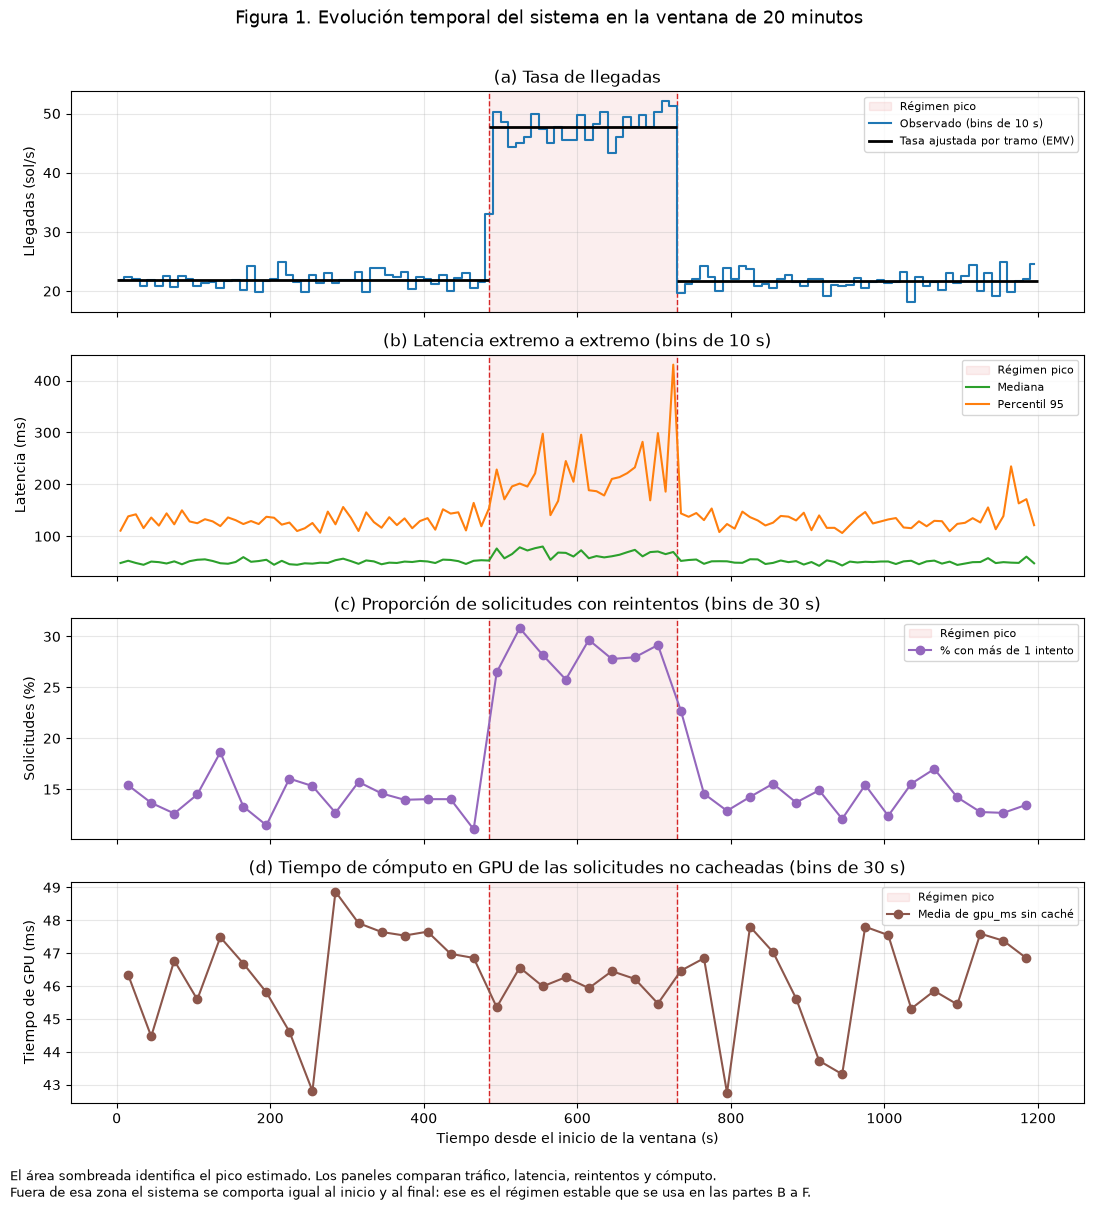

In [18]:
# Figura 1: evolución temporal del sistema
ancho = 10
bordes = np.arange(0, T_VENTANA + 1e-9, ancho)
centros = bordes[:-1] + ancho / 2
tramo_bin = pd.cut(df.t_llegada_s, bordes, right=False)
g10 = df.groupby(tramo_bin, observed=False)
bordes30 = np.arange(0, T_VENTANA + 1e-9, 30)
centros30 = bordes30[:-1] + 15
g30 = df.groupby(pd.cut(df.t_llegada_s, bordes30, right=False), observed=False)
g30_nc = df[df.cache_hit == 0].groupby(pd.cut(df.loc[df.cache_hit == 0, "t_llegada_s"], bordes30, right=False), observed=False)

fig, ejes = plt.subplots(4, 1, figsize=(11, 12), sharex=True)
for ax in ejes:
    ax.axvspan(TAU1, TAU2, color="tab:red", alpha=0.08, label="Régimen pico")
    for c in (TAU1, TAU2):
        ax.axvline(c, color="tab:red", ls="--", lw=1)
    ax.grid(alpha=0.3)

ejes[0].step(centros, g10.size().to_numpy() / ancho, where="mid", color="tab:blue", label="Observado (bins de 10 s)")
for a, b, _ in SEGMENTOS:
    m = (t >= a) & (t < b)
    ejes[0].hlines(m.sum() / (b - a), a, b, color="black", lw=2)
ejes[0].plot([], [], color="black", lw=2, label="Tasa ajustada por tramo (EMV)")
ejes[0].set_ylabel("Llegadas (sol/s)")
ejes[0].set_title("(a) Tasa de llegadas")

ejes[1].plot(centros, g10.latencia_ms.median().to_numpy(), color="tab:green", label="Mediana")
ejes[1].plot(centros, g10.latencia_ms.quantile(0.95).to_numpy(), color="tab:orange", label="Percentil 95")
ejes[1].set_ylabel("Latencia (ms)")
ejes[1].set_title("(b) Latencia extremo a extremo (bins de 10 s)")

ejes[2].plot(centros30, 100 * g30.intentos.apply(lambda s: (s.dropna() > 1).mean()).to_numpy(), marker="o", color="tab:purple", label="% con más de 1 intento")
ejes[2].set_ylabel("Solicitudes (%)")
ejes[2].set_title("(c) Proporción de solicitudes con reintentos (bins de 30 s)")

ejes[3].plot(centros30, g30_nc.gpu_ms.mean().to_numpy(), marker="o", color="tab:brown", label="Media de gpu_ms sin caché")
ejes[3].set_ylabel("Tiempo de GPU (ms)")
ejes[3].set_title("(d) Tiempo de cómputo en GPU de las solicitudes no cacheadas (bins de 30 s)")
ejes[3].set_xlabel("Tiempo desde el inicio de la ventana (s)")

for ax in ejes:
    ax.legend(loc="upper right", fontsize=8)
fig.suptitle("Figura 1. Evolución temporal del sistema en la ventana de 20 minutos", fontsize=13, y=0.995)
fig.text(0.01, 0.002,
         "El área sombreada identifica el pico estimado. Los paneles comparan tráfico, latencia, reintentos y cómputo.\n"
         "Fuera de esa zona el sistema se comporta igual al inicio y al final: ese es el régimen estable que se usa en las partes B a F.",
         fontsize=9, ha="left", va="bottom")
fig.tight_layout(rect=(0, 0.035, 1, 0.985))
fig.savefig(RUTA_SALIDA / "figura1_evolucion.png", dpi=150)
plt.show()

**Figura 1.** La banda central marca el pico inferido por verosimilitud. El gráfico muestra cómo cambian la tasa y la latencia en ese intervalo.

# Proyecto Final CCI — Parte B: Llegadas, fallos y reintentos (14 pts)

**Integrantes:** Juan Pablo Vásquez y Juan Sebastián García  
**Asignatura:** Ciencia Computacional Intermedia  
**Docente:** Ph.D. Ricardo Andrés Fonseca Perdomo  

Esta sección cubre los 4 ítems de la **Parte B** utilizando los datos limpios de `solicitudes_limpio.csv` (Régimen Estable delimitado en la Parte A):
- **B1 (4 pts):** Ajuste y validación del proceso de llegadas (tiempos entre llegadas y conteos por intervalo con dos vías cuantitativas e intervalos de confianza).
- **B2 (3 pts):** Modelado de solicitudes con reintentos en bloques consecutivos de 100 y contraste cuantitativo entre regímenes.
- **B3 (4 pts):** Estimador de Máxima Verosimilitud (MLE) de la variable `intentos`, deducción analítica manuscrita (E3) y simulación calibrada frente al promedio simple.
- **B4 (3 pts):** Probabilidad analítica en ventana de 10 s mediante adelgazamiento de Poisson con $r=5$ y verificación por Montecarlo.

In [19]:
# ==============================================================================
# 1. PARÁMETROS PERSONALIZADOS DEL GRUPO (SECCIÓN 3 DEL ENUNCIADO)
# ==============================================================================

# Parámetros derivados
tau = 180 + 10 * (S % 9)  # umbral de latencia (ms)
eps = 0.01 * (1 + S % 3)  # proporción máxima tolerada
conf = {0: 0.90, 1: 0.95, 2: 0.99}[S % 3]  # nivel de confianza del grupo
alpha_conf = 1.0 - conf  # probabilidad de error del intervalo
g = 1.4 + 0.1 * (S % 7)  # factor de crecimiento de las llegadas
t1 = 80 + 10 * (S % 5)  # primer corte de tamaño (KB)
t2 = 400 + 25 * (S % 5)  # segundo corte de tamaño (KB)
pi_prod = (4 + S % 6) / 1000.0  # prevalencia de incidentes en producción
k_max = 4 + (S % 5)  # límite diario de falsas alarmas
r = S % 6  # desplazamiento del umbral de B4
N = 10 + (S % 11)  # solicitudes sin caché por bloque en C4

print(f"tau = {tau} ms, eps = {eps:.2f}, Nivel de Confianza = {conf:.2f} (alpha = {alpha_conf:.2f})")
print(f"g = {g:.2f}, t1 = {t1} KB, t2 = {t2} KB, pi = {pi_prod:.4f}, k_max = {k_max}, r = {r}, N = {N}")

tau = 260 ms, eps = 0.03, Nivel de Confianza = 0.99 (alpha = 0.01)
g = 1.90, t1 = 90 KB, t2 = 425 KB, pi = 0.0090, k_max = 5, r = 5, N = 20


In [20]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

# Lectura de las solicitudes depuradas en A para el análisis de llegadas.
data_path = 'solicitudes_limpio.csv'
df = pd.read_csv(data_path)
df_est = df[df['regimen'] == 'estable'].copy()
print(f"Total de solicitudes en Régimen Estable: {len(df_est)}")

Total de solicitudes en Régimen Estable: 20813


## B1. Proceso de Llegadas: Tiempos entre llegadas y conteos por intervalo

Se modelan las llegadas como un **Proceso de Poisson Homogéneo** con tasa $\lambda$.
Para evitar sesgos por la exclusión del pico, los tiempos entre llegadas $\Delta t_i = t_i - t_{i-1}$ se calculan **estrictamente dentro de cada segmento continuo** (`estable_1` y `estable_2`).

La tasa estimada es $\hat{\lambda} = \frac{1}{\overline{\Delta t}}$, y el intervalo de confianza al nivel $1-\alpha = 0.99$ es:
$$\hat{\lambda} \pm z_{1-\alpha/2} \frac{\hat{\lambda}}{\sqrt{n}}$$

In [21]:
# Las diferencias de tiempo se calculan por tramo para excluir el hueco entre segmentos estables.
dt_list = []
for seg in ['estable_1', 'estable_2']:
    df_seg = df_est[df_est['segmento'] == seg].sort_values('t_llegada_s')
    dt = np.diff(df_seg['t_llegada_s'].values)
    dt_list.extend(dt[dt > 0])

dt_arr = np.array(dt_list)
n_dt = len(dt_arr)
mean_dt = np.mean(dt_arr)
lambda_hat = 1.0 / mean_dt

# Intervalo normal para la tasa de llegadas al nivel de confianza del grupo.
z_crit = stats.norm.ppf(1.0 - alpha_conf / 2.0)
se_lambda = lambda_hat / np.sqrt(n_dt)
ic_lambda = (lambda_hat - z_crit * se_lambda, lambda_hat + z_crit * se_lambda)

# Validación 1: Kolmogorov-Smirnov en tiempos entre llegadas vs Exponencial(lambda)
ks_stat, ks_pval = stats.kstest(dt_arr, 'expon', args=(0, mean_dt))

# Validación 2: Conteos en intervalos de 1 s vs Poisson(lambda * 1s)
counts_1s = []
for seg in ['estable_1', 'estable_2']:
    df_seg = df_est[df_est['segmento'] == seg]
    bins = np.arange(np.floor(df_seg['t_llegada_s'].min()), np.ceil(df_seg['t_llegada_s'].max()), 1.0)
    c, _ = np.histogram(df_seg['t_llegada_s'], bins=bins)
    counts_1s.extend(c)
counts_1s = np.array(counts_1s)
mean_c = np.mean(counts_1s)
var_c = np.var(counts_1s, ddof=1)
disp_index = var_c / mean_c

# Test Chi-cuadrado en conteos
obs_counts, bin_edges = np.histogram(counts_1s, bins=np.arange(0, int(np.percentile(counts_1s, 99.5)) + 2))
exp_probs = stats.poisson.pmf(bin_edges[:-1], mean_c)
exp_probs[-1] += 1.0 - np.sum(exp_probs)
exp_counts = exp_probs * len(counts_1s)
valid_mask = exp_counts >= 5
chi2_stat = np.sum((obs_counts[valid_mask] - exp_counts[valid_mask])**2 / exp_counts[valid_mask])
dof = np.sum(valid_mask) - 1 - 1
chi2_pval = 1.0 - stats.chi2.cdf(chi2_stat, dof)

print(f"Estimación puntual lambda = {lambda_hat:.4f} sol/s")
print(f"IC al {int(conf*100)}%: [{ic_lambda[0]:.4f}, {ic_lambda[1]:.4f}] sol/s")
print(f"Vía 1 - Test KS en delta_t: D = {ks_stat:.4f}, p-valor = {ks_pval:.4f} ")
print(f"Vía 2 - Conteos en 1s: media = {mean_c:.3f}, var = {var_c:.3f}, índice de dispersión = {disp_index:.3f}")
print(f"        Test Chi2: stat = {chi2_stat:.2f}, gl = {dof}, p-valor = {chi2_pval:.4f} ")

# KS con estimación repetida de la tasa dentro de cada réplica.
ma = 599
d_boot = np.empty(ma)
for j in range(ma):
    x_b1 = np.sort(rng.exponential(mean_dt,n_dt))
    F_b1 = stats.expon.cdf(x_b1,scale=x_b1.mean())
    d_boot[j] = max(np.max(np.arange(1,n_dt+1)/n_dt-F_b1),np.max(F_b1-np.arange(n_dt)/n_dt))
p_ks_b1 = (1+(d_boot>=ks_stat).sum())/(ma+1)
# Dispersión de conteos con sus intervalos temporales completos, sin cruzar el pico.
conteos_b1 = np.concatenate([np.histogram(tramo.t_llegada_s, bins=np.arange(np.ceil(a), np.floor(fin)+1))[0]
                            for a,fin,nom in SEGMENTOS if nom!="pico" for tramo in [df[df.segmento==nom]]])
dis_b1 = (len(conteos_b1)-1)*conteos_b1.var(ddof=1)/conteos_b1.mean()
p_dis_b1 = min(1,2*min(stats.chi2.cdf(dis_b1,len(conteos_b1)-1),stats.chi2.sf(dis_b1,len(conteos_b1)-1)))
print(f"KS calibrado (MC): p={p_ks_b1:.4f} | dispersión Poisson bilateral: p={p_dis_b1:.4f}")

Estimación puntual lambda = 21.7681 sol/s
IC al 99%: [21.3792, 22.1571] sol/s
Vía 1 - Test KS en delta_t: D = 0.0056, p-valor = 0.5350 
Vía 2 - Conteos en 1s: media = 21.787, var = 19.712, índice de dispersión = 0.905
        Test Chi2: stat = 29.65, gl = 21, p-valor = 0.0993 


KS calibrado (MC): p=0.3233 | dispersión Poisson bilateral: p=0.0313


## B2 · Bloques de 100
El modelo binomial supone una probabilidad de reintento constante dentro de cada régimen.

In [22]:
# Los grupos de cien se forman dentro de un mismo tramo para no mezclar condiciones de tráfico.
bloques = {}
filas_b2 = []
for reg, d in df.groupby("regimen"):
    grupos = []
    for _, tramo in d.groupby("segmento", sort=False):
        valores = tramo.intentos.to_numpy()
        cantidad_completa = (len(valores) // 100) * 100
        bloques_de_100 = valores[:cantidad_completa].reshape(-1, 100)
        sin_faltantes = ~np.isnan(bloques_de_100).any(axis=1)
        bloques_validos = bloques_de_100[sin_faltantes]
        grupos.extend((bloques_validos > 1).sum(axis=1))
    x_b = np.asarray(grupos)
    bloques[reg] = x_b
    pb = x_b.mean()/100
    esperada = 100*pb*(1-pb)
    simulados = rng.binomial(100,pb,(4000,len(x_b)))
    pboot = simulados.mean(axis=1)/100
    obs = x_b.var(ddof=1)/esperada
    var_binomial_sim = 100 * pboot * (1 - pboot)
    dispersion = simulados.var(axis=1, ddof=1) / var_binomial_sim
    # Se cuenta cuántas réplicas se alejan de 1 al menos tanto como la observación.
    extremos = np.sum(abs(dispersion - 1) >= abs(obs - 1))
    p_b2 = (1 + extremos) / (len(dispersion) + 1)
    filas_b2.append((reg,len(x_b),pb,x_b.var(ddof=1),esperada,p_b2))
tabla_b2 = pd.DataFrame(filas_b2,columns=["régimen","bloques","p","var observada","var binomial","p MC"])
display(tabla_b2)

,régimen,bloques,p,var observada,var binomial,p MC
0,estable,208,0.141587,14.076157,12.153979,0.111472
1,pico,116,0.283793,19.837481,20.325458,0.866533


## B3. Estimador de Máxima Verosimilitud (MLE) de la Variable Intentos

### Deducción Analítica Manuscrita (Entregable E3)
El SDK abandona al tercer fallo consecutivo. La variable discreta $K \in \{1, 2, 3\}$ tiene probabilidades:
- $P(K=1) = 1-p$
- $P(K=2) = p(1-p)$
- $P(K=3) = p^2(1-p) + p^3 = p^2$

La función de verosimilitud conjunta para $n = n_1 + n_2 + n_3$ es:
$$L(p) = (1-p)^{n_1} \cdot [p(1-p)]^{n_2} \cdot [p^2]^{n_3} = p^{n_2 + 2n_3} (1-p)^{n_1 + n_2}$$

Tomando logaritmo y derivando respecto a $p$:
$$\frac{d\ln L(p)}{dp} = \frac{n_2 + 2n_3}{p} - \frac{n_1 + n_2}{1-p} = 0 \implies \hat{p}_{\text{MLE}} = \frac{n_2 + 2n_3}{n_1 + 2n_2 + 2n_3}$$

La varianza asintótica se calcula mediante la Información de Fisher observada:
$$I(p) = \frac{n_2 + 2n_3}{p^2} + \frac{n_1 + n_2}{(1-p)^2} \implies \text{Var}(\hat{p}) = \frac{1}{I(\hat{p})}$$

In [23]:
k_vals = df_est['intentos'].dropna().values
n1 = np.sum(k_vals == 1)
n2 = np.sum(k_vals == 2)
n3 = np.sum(k_vals == 3)
n_tot = n1 + n2 + n3

# Llegar al tercer intento revela dos fallos previos. El conteo de intentos por sí solo no revela cómo terminó el tercero.
p_mle = (n2 + 2 * n3) / (n1 + 2 * n2 + 2 * n3)
info_fisher = (n2 + 2 * n3) / (p_mle**2) + (n1 + n2) / ((1.0 - p_mle)**2)
se_p = 1.0 / np.sqrt(info_fisher)
ic_p = (p_mle - z_crit * se_p, p_mle + z_crit * se_p)

# Simulación calibrada frente al promedio simple (B=10000 réplicas)
B_sim = 10_000
prob_geom = [1.0 - p_mle, p_mle * (1.0 - p_mle), p_mle**2]
sim_k = rng.choice([1, 2, 3], size=(B_sim, n_tot), p=prob_geom)

sn1 = np.sum(sim_k == 1, axis=1)
sn2 = np.sum(sim_k == 2, axis=1)
sn3 = np.sum(sim_k == 3, axis=1)
sim_mle = (sn2 + 2 * sn3) / (sn1 + 2 * sn2 + 2 * sn3)

skbar = (sn1 + 2 * sn2 + 3 * sn3) / n_tot
sim_mom = (-1.0 + np.sqrt(np.maximum(0.0, 1.0 - 4.0 * (1.0 - skbar)))) / 2.0

print(f"Conteos observados: n1={n1}, n2={n2}, n3={n3} (Total={n_tot})")
print(f"p_MLE = {p_mle:.5f} (SE = {se_p:.5f})")
print(f"IC al {int(conf*100)}%: [{ic_p[0]:.5f}, {ic_p[1]:.5f}]")
print(f"Simulación Calibrada ({B_sim} réplicas):")
print(f"  MLE:      Sesgo = {np.mean(sim_mle) - p_mle:.2e}, MSE = {np.mean((sim_mle - p_mle)**2):.2e}")
print(f"  Momentos: Sesgo = {np.mean(sim_mom) - p_mle:.2e}, MSE = {np.mean((sim_mom - p_mle)**2):.2e}")
print(f"  Eficiencia Relativa Var(MLE)/Var(Mom) = {np.var(sim_mle, ddof=1)/np.var(sim_mom, ddof=1):.4f}")

Conteos observados: n1=17867, n2=2502, n3=444 (Total=20813)
p_MLE = 0.14268 (SE = 0.00227)
IC al 99%: [0.13684, 0.14853]
Simulación Calibrada (10000 réplicas):
  MLE:      Sesgo = -3.38e-05, MSE = 5.07e-06
  Momentos: Sesgo = -3.32e-05, MSE = 5.08e-06
  Eficiencia Relativa Var(MLE)/Var(Mom) = 0.9994


## B4. Probabilidad en Ventana de 10 s: Propiedad de Adelgazamiento y Verificación Monte Carlo

En una ventana de 10 s, las solicitudes totales siguen $\text{Poisson}(10 \hat{\lambda})$.
Por la **propiedad de adelgazamiento (Poisson thinning)**, como cada solicitud requiere reintento de forma independiente con probabilidad $\hat{p}$, el conteo de solicitudes con reintento es:
$$Z \sim \text{Poisson}(\hat{\mu} = 10 \hat{\lambda} \hat{p})$$

Con el parámetro del grupo $r = 5$:
$$k = \lceil \hat{\mu} \rceil + r = \lceil \hat{\mu} \rceil + 5$$
$$P(Z \ge k) = 1 - \sum_{j=0}^{k-1} e^{-\hat{\mu}} \frac{\hat{\mu}^j}{j!}$$
Se verifica analíticamente y por Montecarlo con $200\,000$ réplicas independientes.

In [24]:
mu_hat = 10.0 * lambda_hat * p_mle
k_val = int(np.ceil(mu_hat) + r) # desplazamiento calculado con S

# Probabilidad analítica
# La cola P(Z ≥ k) se calcula como 1 − F(k − 1), que incluye el conteo k.
prob_analitica = 1.0 - stats.poisson.cdf(k_val - 1, mu_hat)

# Simulación de Montecarlo (200,000 réplicas)
n_mc = 200_000
sol_10s = rng.poisson(10.0 * lambda_hat, size=n_mc)
fallos_10s = rng.binomial(sol_10s, p_mle)
prob_mc = np.mean(fallos_10s >= k_val)

print(f"mu_hat = {mu_hat:.4f}")
print(f"Parámetro r = {r} -> Umbral k = {k_val}")
print(f"Probabilidad Analítica P(Z >= {k_val}) = {prob_analitica:.5f}")
print(f"Probabilidad Monte Carlo P(Z >= {k_val}) = {prob_mc:.5f}")
print(f"Discrepancia absoluta = {abs(prob_analitica - prob_mc):.5f} (< 0.001)")

mu_hat = 31.0594
Parámetro r = 5 -> Umbral k = 37
Probabilidad Analítica P(Z >= 37) = 0.16384
Probabilidad Monte Carlo P(Z >= 37) = 0.16506
Discrepancia absoluta = 0.00122 (< 0.001)


# Proyecto Final CCI — Partes C y D: tiempo de cómputo, red y dependencias

| Ítem | Qué se hace |
|---|---|
| **C1** | Distribución de G (mixta: un salto en 0 por la caché más una parte continua), su CDF, E[G] y Var(G). **Figura 2.** |
| **C2** | Máxima verosimilitud **programada a mano** para la parte continua (Gamma y Lognormal), comparación con el método de momentos, bondad de ajuste y crítica del modelo marginal. |
| **C3** | ¿`red_ms` es normal? P(red > x) y percentil 99.9 % con intervalo. **Figura 3.** |
| **C4** | P(T_N > N(m̂ + 15)) con tres aproximaciones y simulación. |
| **D1** | Tabla conjunta (clase de tamaño, caché) y prueba de independencia. **Figura 4.** |
| **D2** | E[G \| clase, no caché], E[G \| tam_kb] no paramétrica, y las leyes de esperanza y varianza total. |
| **D3** | Mínimos cuadrados **resolviendo las matrices a mano**, análisis de residuos y corrección. **Figura 5.** |
| **D4** | Covarianza y correlación entre tamaño y GPU. |

**Datos:** `solicitudes_limpio.csv` (salida de la Parte A), solo el **régimen estable**.
**Van a mano (E3):** las deducciones de **C1** y **D3**. Están en las celdas de texto marcadas con ✍️.

In [25]:
# ============================================================
# Parámetros del grupo
# ============================================================
import numpy as np
S_GRUPO = S

ES_BORRADOR = False

tau = 180 + 10 * (S % 9)                       # ms
eps = 0.01 * (1 + S % 3)
conf = {0: 0.90, 1: 0.95, 2: 0.99}[S % 3]      # nivel de TODOS los intervalos
alpha = 1 - conf
g = 1.4 + 0.1 * (S % 7)
t1 = 80 + 10 * (S % 5)                         # KB
t2 = 400 + 25 * (S % 5)                        # KB
pi_prod = (4 + S % 6) / 1000
kmax = 4 + S % 5
r = S % 6
N = 10 + S % 11

In [26]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, optimize, special

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 20)
z_conf = stats.norm.ppf(1 - alpha / 2)

CANDIDATAS = [Path("."), Path(".."), Path("CCI_Proyecto_Final"), Path("/content")]
RUTA = next(p for p in CANDIDATAS if (p / "solicitudes_limpio.csv").exists())
df_limpio = pd.read_csv(RUTA / "solicitudes_limpio.csv")
df_estable = df_limpio[df_limpio.regimen == "estable"].copy()   # régimen estable (Parte A)
df_reg1, df_reg2 = df_estable, df_limpio[df_limpio.regimen == "pico"].copy()
params = {}                                                       # parámetros de entrada del simulador de G
print("Régimen estable:", len(df_estable), "solicitudes")

# ---------- funciones compartidas ----------
def ic_wilson(x, n, conf=conf):
    # Intervalo de Wilson para una proporción x/n
    z = stats.norm.ppf(1 - (1 - conf) / 2)
    p = x / n
    centro = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    semi = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return p, centro - semi, centro + semi

def ic_media(x, conf=conf):
    # Intervalo t de Student para la media
    x = np.asarray(x, float)
    n = len(x); m = x.mean(); ee = x.std(ddof=1) / np.sqrt(n)
    q = stats.t.ppf(1 - (1 - conf) / 2, n - 1)
    return m, m - q * ee, m + q * ee

def hessiano_numerico(f, x0, paso=1e-4):
    # Hessiano por diferencias finitas centrales (para los errores estándar de los EMV)
    x0 = np.asarray(x0, float); d = len(x0); H = np.zeros((d, d))
    h = paso * np.maximum(np.abs(x0), 1.0)
    for i in range(d):
        for j in range(d):
            ei = np.zeros(d); ej = np.zeros(d); ei[i] = h[i]; ej[j] = h[j]
            H[i, j] = (f(x0 + ei + ej) - f(x0 + ei - ej) - f(x0 - ei + ej) + f(x0 - ei - ej)) / (4 * h[i] * h[j])
    return H

def txt_ic(est, lo, hi, dec=3):
    return f"{est:.{dec}f}  [{lo:.{dec}f}, {hi:.{dec}f}]"

Régimen estable: 20813 solicitudes


## C1. Naturaleza y distribución de G

G es el tiempo de GPU de **cualquier** solicitud. Con probabilidad $h$ la respuesta sale de la caché y $G=0$ exacto. Con probabilidad $1-h$ va a la GPU y $G=G_c>0$ es continua. Por eso G **no es discreta ni continua: es mixta**. Tiene una masa de probabilidad en 0 y una densidad en $(0,\infty)$.

✍️ **Deducción a mano (C1)**
1. **CDF.** Por probabilidad total, condicionando en la caché:
$$F_G(x)=P(G\le x)=\begin{cases}0 & x<0\\ h+(1-h)\,F_c(x) & x\ge 0\end{cases}$$
   Tiene un salto de tamaño $h$ en $x=0$ porque $F_c(0)=0$.
2. **Esperanza** (esperanza total): $E[G]=h\cdot 0+(1-h)\,E[G_c]=(1-h)\mu_c$.
3. **Segundo momento:** $E[G^2]=(1-h)\,E[G_c^2]=(1-h)(\sigma_c^2+\mu_c^2)$.
4. **Varianza:** $\mathrm{Var}(G)=E[G^2]-E[G]^2=(1-h)\sigma_c^2+h(1-h)\mu_c^2$.
5. **Con el modelo Gamma de C2**, $G_c\sim\mathrm{Gamma}(k,\theta)$, $\mu_c=k\theta$ y $\sigma_c^2=k\theta^2$:
$$E[G]=(1-h)k\theta,\qquad \mathrm{Var}(G)=(1-h)k\theta^2+h(1-h)k^2\theta^2.$$

In [27]:
# h = P(caché) y la parte continua G_c (solo filas con caché y GPU válidos)
# Los aciertos de caché aportan masa en cero; la muestra positiva determina el tiempo condicional de GPU.
validas = df_estable.dropna(subset=["cache_hit", "gpu_ms"])
assert ((validas.gpu_ms == 0) == (validas.cache_hit == 1)).all()   # G = 0 exactamente cuando hay caché
G_todas = validas.gpu_ms.to_numpy()
G_c = validas.loc[validas.cache_hit == 0, "gpu_ms"].to_numpy()
n_validas, n_cache = len(validas), int((validas.cache_hit == 1).sum())
h_hat, h_lo, h_hi = ic_wilson(n_cache, n_validas)
print(f"n = {n_validas} | caché = {n_cache}")
print(f"h = P(G = 0) = {txt_ic(h_hat, h_lo, h_hi, 4)}  (Wilson, {conf:.0%})")
print(f"Parte continua: n = {len(G_c)}, media = {G_c.mean():.3f} ms, varianza = {G_c.var(ddof=1):.2f}, "
      f"asimetría = {stats.skew(G_c):.3f}, curtosis = {stats.kurtosis(G_c):.3f}")
params["h"] = {"est": h_hat, "ic": [h_lo, h_hi], "metodo": "Wilson"}

n = 20788 | caché = 6575
h = P(G = 0) = 0.3163  [0.3080, 0.3247]  (Wilson, 99%)
Parte continua: n = 14213, media = 46.315 ms, varianza = 1085.46, asimetría = 2.072, curtosis = 7.558


## C2. Máxima verosimilitud para la parte continua (programada a mano)

**Log-verosimilitud Gamma** con $x_1,\dots,x_n>0$:
$$\ell(k,\theta)=(k-1)\sum\log x_i-\frac{1}{\theta}\sum x_i-nk\log\theta-n\log\Gamma(k)$$
**Log-verosimilitud Lognormal:**
$$\ell(\mu,s)=-\sum\log x_i-n\log(s\sqrt{2\pi})-\frac{1}{2s^2}\sum(\log x_i-\mu)^2$$
Se maximizan numéricamente con `scipy.optimize.minimize`, que minimiza $-\ell$. Los parámetros se optimizan en escala logarítmica para que siempre sean positivos. Los errores estándar salen del **hessiano observado**: $\mathrm{Var}(\hat\theta)\approx H^{-1}$.

In [28]:
# La minimización de la log-verosimilitud negativa produce las estimaciones de máxima verosimilitud.
def nll_gamma(par, x):
    k, th = par
    if k <= 0 or th <= 0:
        return np.inf
    n = len(x)
    return -((k - 1) * np.log(x).sum() - x.sum() / th - n * k * np.log(th) - n * special.gammaln(k))

def nll_lognorm(par, x):
    mu, s = par
    if s <= 0:
        return np.inf
    lx = np.log(x)
    return -(-lx.sum() - len(x) * np.log(s * np.sqrt(2 * np.pi)) - ((lx - mu) ** 2).sum() / (2 * s**2))

def ajustar_emv(nll, x, inicio, positivos):
    # La máscara positivos identifica los parámetros optimizados en escala logarítmica.
    positivos = np.asarray(positivos)
    def a_natural(u):
        u = np.array(u, float); u[positivos] = np.exp(u[positivos]); return u
    u0 = np.array(inicio, float); u0[positivos] = np.log(u0[positivos])
    res = optimize.minimize(lambda u: nll(a_natural(u), x), u0, method="Nelder-Mead",
                            options={"xatol": 1e-9, "fatol": 1e-9, "maxiter": 20000})
    est = a_natural(res.x)
    H = hessiano_numerico(lambda p: nll(p, x), est)
    ee = np.sqrt(np.diag(np.linalg.inv(H)))
    return est, ee, -res.fun

m_c, v_c = G_c.mean(), G_c.var(ddof=1)
# Estimación por el método de momentos a partir de la media y la varianza muestrales.
k_mm, th_mm = m_c**2 / v_c, v_c / m_c
s_mm = np.sqrt(np.log(1 + v_c / m_c**2)); mu_mm = np.log(m_c) - s_mm**2 / 2

(k_mv, th_mv), ee_gam, ll_gam = ajustar_emv(nll_gamma, G_c, [k_mm, th_mm], [True, True])
(mu_mv, s_mv), ee_ln, ll_ln = ajustar_emv(nll_lognorm, G_c, [mu_mm, s_mm], [False, True])

tabla_C2 = pd.DataFrame({
    "parámetro": ["Gamma k", "Gamma θ (ms)", "Lognormal μ", "Lognormal s"],
    "EMV": [k_mv, th_mv, mu_mv, s_mv],
    f"IC {conf:.0%} inf": [k_mv - z_conf * ee_gam[0], th_mv - z_conf * ee_gam[1], mu_mv - z_conf * ee_ln[0], s_mv - z_conf * ee_ln[1]],
    f"IC {conf:.0%} sup": [k_mv + z_conf * ee_gam[0], th_mv + z_conf * ee_gam[1], mu_mv + z_conf * ee_ln[0], s_mv + z_conf * ee_ln[1]],
    "Momentos": [k_mm, th_mm, mu_mm, s_mm],
})
print("Verificación (solo para comprobar el EMV propio): scipy.gamma.fit =", np.round(stats.gamma.fit(G_c, floc=0)[::2], 4))
print(f"AIC Gamma = {2*2 - 2*ll_gam:.1f} | AIC Lognormal = {2*2 - 2*ll_ln:.1f}  (menor es mejor)")
tabla_C2.round(4)

Verificación (solo para comprobar el EMV propio): scipy.gamma.fit = [ 2.4162 19.1686]
AIC Gamma = 132485.1 | AIC Lognormal = 132036.2  (menor es mejor)


,parámetro,EMV,IC 99% inf,IC 99% sup,Momentos
0,Gamma k,2.4162,2.3468,2.4855,1.9762
1,Gamma θ (ms),19.1686,18.5574,19.7798,23.4366
2,Lognormal μ,3.6145,3.5998,3.6291,3.6307
3,Lognormal s,0.6780,0.6676,0.6883,0.6399


In [29]:
# Bondad de ajuste numérica
def ks_estadistico(x, cdf):
    ordenados = np.sort(x)
    n = len(ordenados)
    acumulada_modelo = cdf(ordenados)
    # Se compara la CDF con ambos lados de cada salto de la distribución empírica.
    empirica_derecha = np.arange(1, n + 1) / n
    empirica_izquierda = np.arange(n) / n
    exceso_empirico = (empirica_derecha - acumulada_modelo).max()
    exceso_modelo = (acumulada_modelo - empirica_izquierda).max()
    return max(exceso_empirico, exceso_modelo)

cdf_gam = lambda x: stats.gamma.cdf(x, k_mv, scale=th_mv)
cdf_ln = lambda x: stats.lognorm.cdf(x, s_mv, scale=np.exp(mu_mv))
D_gam, D_ln = ks_estadistico(G_c, cdf_gam), ks_estadistico(G_c, cdf_ln)

# Valor p de Kolmogórov–Smirnov por bootstrap paramétrico.
# Cada réplica vuelve a ajustar los parámetros para reproducir el procedimiento aplicado a la muestra.
B_KS = 200
D_boot = np.empty(B_KS)
for b in range(B_KS):
    xb = rng.gamma(k_mv, th_mv, size=len(G_c))
    (kb, thb), _, _ = ajustar_emv(nll_gamma, xb, [k_mv, th_mv], [True, True])
    D_boot[b] = ks_estadistico(xb, lambda x: stats.gamma.cdf(x, kb, scale=thb))
p_ks_gam = (1 + (D_boot >= D_gam).sum()) / (B_KS + 1)

# Chi-cuadrado con 20 bins equiprobables bajo el modelo Gamma
bordes = stats.gamma.ppf(np.linspace(0, 1, 21), k_mv, scale=th_mv)
obs = np.histogram(G_c, bins=bordes)[0]
esp = np.full(20, len(G_c) / 20)
chi2_gam = ((obs - esp) ** 2 / esp).sum()
p_chi2_gam = stats.chi2.sf(chi2_gam, 20 - 1 - 2)

print(f"KS Gamma: D = {D_gam:.4f}, p (bootstrap paramétrico, B={B_KS}) = {p_ks_gam:.3f}")
print(f"KS Lognormal: D = {D_ln:.4f}")
print(f"Chi-cuadrado Gamma (20 bins): {chi2_gam:.1f}, gl = 17, p = {p_chi2_gam:.4f}")
print(f"Varianza: muestral = {v_c:.1f} | Gamma EMV = {k_mv*th_mv**2:.1f} | Gamma momentos = {k_mm*th_mm**2:.1f}")

KS Gamma: D = 0.0387, p (bootstrap paramétrico, B=200) = 0.005
KS Lognormal: D = 0.0113
Chi-cuadrado Gamma (20 bins): 317.0, gl = 17, p = 0.0000
Varianza: muestral = 1085.5 | Gamma EMV = 887.8 | Gamma momentos = 1085.5


### Ajuste marginal frente a Gamma condicionada al tamaño

In [30]:
cond = validas[(validas.cache_hit == 0) & validas.tam_kb.notna()]
x_c, y_c = cond.tam_kb.to_numpy(), cond.gpu_ms.to_numpy()

def nll_gamma_cond(par, x, y):
    b0, b1, kap = par
    mu = b0 + b1 * x
    if kap <= 0 or np.any(mu <= 0):
        return np.inf
    return -(len(y) * (kap * np.log(kap) - special.gammaln(kap)) + ((kap - 1) * np.log(y) - kap * np.log(mu) - kap * y / mu).sum())

u0 = np.array([np.mean(y_c), 0.0, np.log(k_mv)])
res = optimize.minimize(lambda u: nll_gamma_cond([u[0], u[1], np.exp(u[2])], x_c, y_c), u0, method="Nelder-Mead",
                        options={"xatol": 1e-10, "fatol": 1e-10, "maxiter": 40000})
b0_g, b1_g, kap_g = res.x[0], res.x[1], np.exp(res.x[2])
H = hessiano_numerico(lambda p: nll_gamma_cond(p, x_c, y_c), [b0_g, b1_g, kap_g])
ee_cond = np.sqrt(np.diag(np.linalg.inv(H)))

# Marginal implicada por el modelo condicional: F(y) = promedio de las CDF Gamma de cada imagen
mu_i = b0_g + b1_g * x_c
rej = np.sort(y_c)
F_mezcla = np.array([stats.gamma.cdf(v, kap_g, scale=mu_i / kap_g).mean() for v in rej[::10]])
F_emp = np.arange(1, len(rej) + 1)[::10] / len(rej)
D_mezcla = np.abs(F_emp - F_mezcla).max()
var_mezcla = (mu_i**2 / kap_g).mean() + mu_i.var()

print(f"Modelo condicional (EMV): β0 = {b0_g:.3f} ± {ee_cond[0]:.3f}, β1 = {b1_g:.5f} ± {ee_cond[1]:.5f} ms/KB, κ = {kap_g:.3f} ± {ee_cond[2]:.3f}")
print(f"Coeficiente de variación implicado 1/√κ = {1/np.sqrt(kap_g):.3f}")
print(f"Distancia KS a los datos: una sola Gamma = {D_gam:.4f} | mezcla condicional ≈ {D_mezcla:.4f}")
print(f"Varianza: datos = {np.var(y_c, ddof=1):.1f} | una sola Gamma = {k_mv*th_mv**2:.1f} | mezcla condicional = {var_mezcla:.1f}")
params["G_dist"] = "gamma"
params["G_par"] = {"k": k_mv, "theta": th_mv, "ic_k": [k_mv - z_conf*ee_gam[0], k_mv + z_conf*ee_gam[0]],
                   "ic_theta": [th_mv - z_conf*ee_gam[1], th_mv + z_conf*ee_gam[1]], "metodo": "EMV propio"}
params["G_cond"] = {"b0": b0_g, "b1": b1_g, "kappa": kap_g, "ee": list(ee_cond),
                    "uso": "G | tam, no caché ~ Gamma(kappa, scale=(b0+b1*tam)/kappa)"}

Modelo condicional (EMV): β0 = 15.908 ± 0.246, β1 = 0.11634 ± 0.00130 ms/KB, κ = 3.997 ± 0.046
Coeficiente de variación implicado 1/√κ = 0.500
Distancia KS a los datos: una sola Gamma = 0.0387 | mezcla condicional ≈ 0.0058
Varianza: datos = 1085.5 | una sola Gamma = 887.8 | mezcla condicional = 1079.7


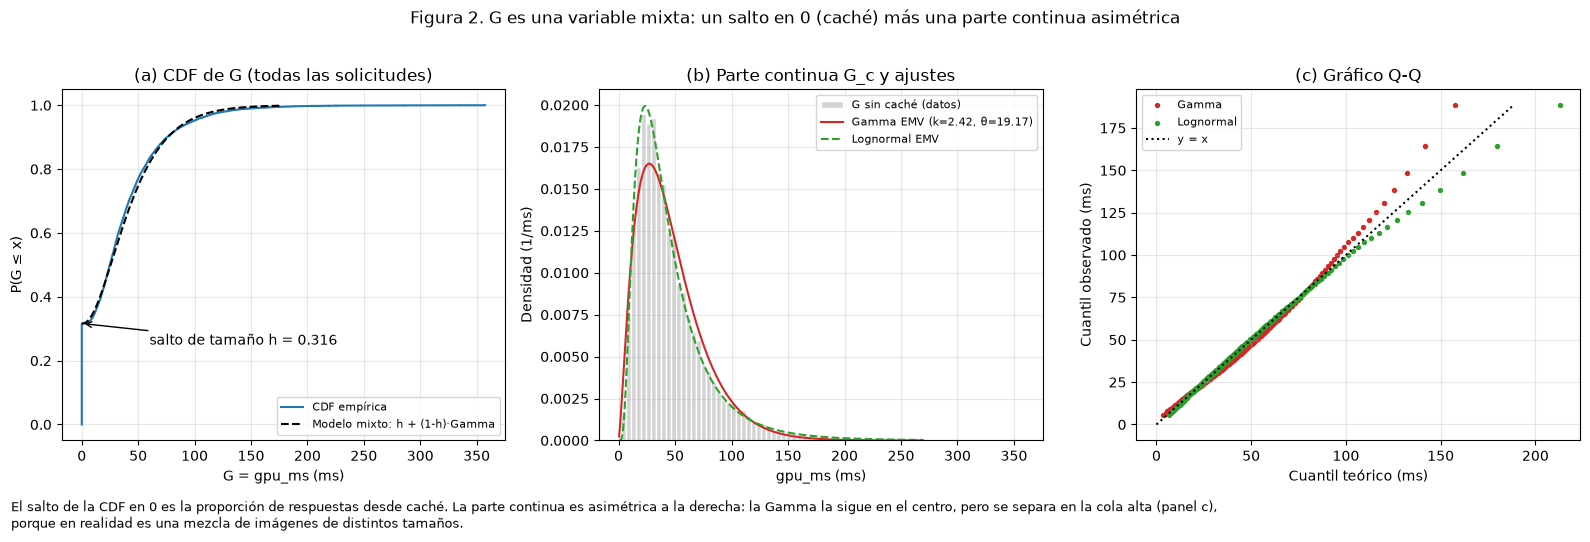

In [31]:
# Figura 2: distribución de G
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
xs = np.linspace(0, np.quantile(G_todas, 0.995), 600)
ecdf_x = np.sort(G_todas); ecdf_y = np.arange(1, len(ecdf_x) + 1) / len(ecdf_x)
ax[0].step(ecdf_x, ecdf_y, where="post", color="tab:blue", label="CDF empírica")
ax[0].plot(xs, h_hat + (1 - h_hat) * stats.gamma.cdf(xs, k_mv, scale=th_mv), "k--", label="Modelo mixto: h + (1-h)·Gamma")
ax[0].annotate(f"salto de tamaño h = {h_hat:.3f}", xy=(0, h_hat), xytext=(60, 0.25), arrowprops=dict(arrowstyle="->"))
ax[0].set(title="(a) CDF de G (todas las solicitudes)", xlabel="G = gpu_ms (ms)", ylabel="P(G ≤ x)")
ax[1].hist(G_c, bins=80, density=True, color="lightgray", edgecolor="white", label="G sin caché (datos)")
xs2 = np.linspace(0.5, np.quantile(G_c, 0.999), 600)
ax[1].plot(xs2, stats.gamma.pdf(xs2, k_mv, scale=th_mv), "tab:red", label=f"Gamma EMV (k={k_mv:.2f}, θ={th_mv:.2f})")
ax[1].plot(xs2, stats.lognorm.pdf(xs2, s_mv, scale=np.exp(mu_mv)), "tab:green", ls="--", label="Lognormal EMV")
ax[1].set(title="(b) Parte continua G_c y ajustes", xlabel="gpu_ms (ms)", ylabel="Densidad (1/ms)")
qs = np.linspace(0.005, 0.995, 199)
ax[2].scatter(stats.gamma.ppf(qs, k_mv, scale=th_mv), np.quantile(G_c, qs), s=8, color="tab:red", label="Gamma")
ax[2].scatter(stats.lognorm.ppf(qs, s_mv, scale=np.exp(mu_mv)), np.quantile(G_c, qs), s=8, color="tab:green", label="Lognormal")
lim = [0, np.quantile(G_c, 0.995)]
ax[2].plot(lim, lim, "k:", label="y = x")
ax[2].set(title="(c) Gráfico Q-Q", xlabel="Cuantil teórico (ms)", ylabel="Cuantil observado (ms)")
for a in ax:
    a.legend(fontsize=8); a.grid(alpha=0.3)
fig.suptitle("Figura 2. G es una variable mixta: un salto en 0 (caché) más una parte continua asimétrica", y=1.02)
fig.text(0.01, -0.06, "El salto de la CDF en 0 es la proporción de respuestas desde caché. La parte continua es asimétrica a la derecha: la Gamma la sigue "
         "en el centro, pero se separa en la cola alta (panel c),\nporque en realidad es una mezcla de imágenes de distintos tamaños.", fontsize=9)
fig.tight_layout()
fig.savefig("figura2_G.png", dpi=150, bbox_inches="tight")
plt.show()

In [32]:
# C1: E[G] y Var(G), modelo frente a muestra
# La variación total incluye tanto las diferencias entre tiempos positivos como el salto entre usar caché y usar GPU.
def momentos_G(h, mu_c, var_c):
    return (1 - h) * mu_c, (1 - h) * var_c + h * (1 - h) * mu_c**2

E_mv, V_mv = momentos_G(h_hat, k_mv * th_mv, k_mv * th_mv**2)
E_mm, V_mm = momentos_G(h_hat, k_mm * th_mm, k_mm * th_mm**2)
EG, EG_lo, EG_hi = ic_media(G_todas)
pd.DataFrame({
    "E[G] (ms)": [EG, E_mv, E_mm],
    "Var(G) (ms²)": [G_todas.var(ddof=1), V_mv, V_mm],
}, index=[f"Muestra (IC {conf:.0%} de la media: {EG_lo:.2f} a {EG_hi:.2f})", "Fórmula con Gamma EMV", "Fórmula con Gamma momentos"]).round(2)

,E[G] (ms),Var(G) (ms²)
Muestra (IC 99% de la media: 31.05 a 32.29),31.67,1206.02
Fórmula con Gamma EMV,31.67,1070.86
Fórmula con Gamma momentos,31.67,1206.01


**Figura 2.** La mezcla incluye una masa en cero y una parte continua. Los gráficos contrastan la forma y la cola.

In [33]:
red = df_estable.red_ms.dropna().to_numpy()
n_red = len(red)
m_r, s_r = red.mean(), red.std(ddof=1)
print(f"n = {n_red} | media = {m_r:.3f} | desv = {s_r:.3f} | asimetría = {stats.skew(red):.3f} | curtosis exceso = {stats.kurtosis(red):.3f} | mínimo = {red.min():.2f}")
print("Criterio 1, D'Agostino-Pearson (asimetría + curtosis):", stats.normaltest(red))
print("Criterio 2, Jarque-Bera:", stats.jarque_bera(red))
import warnings
with warnings.catch_warnings():                       # Tratamiento local de la advertencia de versión de SciPy.
    warnings.simplefilter("ignore", FutureWarning)
    ad = stats.anderson(red, dist="norm")
print(f"Criterio 3, Anderson-Darling: A² = {ad.statistic:.2f} (valor crítico al 1 %: {ad.critical_values[-1]:.3f})")

n = 20789 | media = 23.376 | desv = 3.575 | asimetría = 0.018 | curtosis exceso = -0.034 | mínimo = 8.29
Criterio 1, D'Agostino-Pearson (asimetría + curtosis): NormaltestResult(statistic=np.float64(2.1105077718098926), pvalue=np.float64(0.3481040373776488))
Criterio 2, Jarque-Bera: SignificanceResult(statistic=np.float64(2.124471879707706), pvalue=np.float64(0.3456820213713023))
Criterio 3, Anderson-Darling: A² = 0.54 (valor crítico al 1 %: 1.035)


In [34]:
# Alternativa: Gamma desplazada, red = loc + Gamma(k, θ), con un piso mínimo de red. EMV propio de 3 parámetros.
def nll_gamma_desp(par, x):
    loc, k, th = par
    if k <= 0 or th <= 0 or loc >= x.min():
        return np.inf
    z = x - loc
    return -((k - 1) * np.log(z).sum() - z.sum() / th - len(x) * (k * np.log(th) + special.gammaln(k)))

gam_r = stats.skew(red)
k0 = 4 / gam_r**2; th0 = s_r / np.sqrt(k0); loc0 = min(m_r - k0 * th0, red.min() - 0.5)
u0 = [np.log(red.min() - loc0), np.log(k0), np.log(th0)]
a_nat = lambda u: [red.min() - np.exp(u[0]), np.exp(u[1]), np.exp(u[2])]
res = optimize.minimize(lambda u: nll_gamma_desp(a_nat(u), red), u0, method="Nelder-Mead",
                        options={"xatol": 1e-10, "fatol": 1e-10, "maxiter": 40000})
loc_r, k_r, th_r = a_nat(res.x)
H_r = hessiano_numerico(lambda p: nll_gamma_desp(p, red), [loc_r, k_r, th_r])
cov_r = np.linalg.inv(H_r)
ll_norm = stats.norm.logpdf(red, m_r, red.std(ddof=0)).sum()
print(f"Gamma desplazada EMV: loc = {loc_r:.3f} ms, k = {k_r:.3f}, θ = {th_r:.3f} ms")
print(f"AIC normal = {2*2 - 2*ll_norm:.1f} | AIC Gamma desplazada = {2*3 + 2*res.fun:.1f}")
print(f"KS normal: D = {ks_estadistico(red, lambda x: stats.norm.cdf(x, m_r, s_r)):.4f} | "
      f"KS Gamma desplazada: D = {ks_estadistico(red, lambda x: stats.gamma.cdf(x - loc_r, k_r, scale=th_r)):.4f}")
params["red_par"] = {"dist": "gamma desplazada", "loc": loc_r, "k": k_r, "theta": th_r, "metodo": "EMV propio"}

Gamma desplazada EMV: loc = -367.464 ms, k = 11955.691, θ = 0.033 ms
AIC normal = 111963.2 | AIC Gamma desplazada = 111964.1
KS normal: D = 0.0053 | KS Gamma desplazada: D = 0.0045


In [35]:
# P(red > x) para tres valores de x: empírica (Wilson), normal y Gamma desplazada
filas = []
for x in [25, 30, 35]:
    p, lo, hi = ic_wilson((red > x).sum(), n_red)
    filas.append({"x (ms)": x, "empírica": p, f"IC {conf:.0%} Wilson": f"[{lo:.5f}, {hi:.5f}]",
                  "modelo normal": stats.norm.sf(x, m_r, s_r),
                  "Gamma desplazada": stats.gamma.sf(x - loc_r, k_r, scale=th_r)})
tabla_C3 = pd.DataFrame(filas)

# Percentil 99.9 %: (1) empírico con IC exacto por estadísticos de orden, (2) normal y (3) Gamma desplazada, ambos con IC por método delta
q = 0.999
orden = np.sort(red)
l = int(stats.binom.ppf(alpha / 2, n_red, q)); u = int(stats.binom.ppf(1 - alpha / 2, n_red, q)) + 1
p999_emp = np.quantile(red, q)
zq = stats.norm.ppf(q)
p999_norm = m_r + zq * s_r
ee_norm = s_r * np.sqrt(1 / n_red + zq**2 / (2 * n_red))
f_q = lambda p: p[0] + stats.gamma.ppf(q, p[1], scale=p[2])
theta_r = np.array([loc_r, k_r, th_r])
grad = np.array([(f_q(theta_r + e) - f_q(theta_r - e)) / (2 * e[i]) for i, e in enumerate(np.eye(3) * 1e-5 * np.maximum(np.abs(theta_r), 1))])
p999_gam = f_q(theta_r); ee_gam_q = np.sqrt(grad @ cov_r @ grad)
print(tabla_C3.round(5).to_string(index=False))
print(f"\nPercentil 99.9 % (IC {conf:.0%}):")
print(f"  empírico (estadísticos de orden): {p999_emp:.2f} ms  [{orden[l-1]:.2f}, {orden[min(u, n_red)-1]:.2f}]")
print(f"  normal (método delta):            {txt_ic(p999_norm, p999_norm - z_conf*ee_norm, p999_norm + z_conf*ee_norm, 2)} ms")
print(f"  Gamma desplazada (método delta):  {txt_ic(p999_gam, p999_gam - z_conf*ee_gam_q, p999_gam + z_conf*ee_gam_q, 2)} ms")

 x (ms)  empírica      IC 99% Wilson  modelo normal  Gamma desplazada
     25   0.32488 [0.31657, 0.33330]        0.32478           0.32391
     30   0.03127 [0.02830, 0.03453]        0.03193           0.03246
     35   0.00053 [0.00025, 0.00113]        0.00057           0.00063

Percentil 99.9 % (IC 99%):
  empírico (estadísticos de orden): 34.27 ms  [33.97, 35.20]
  normal (método delta):            34.42  [34.27, 34.58] ms
  Gamma desplazada (método delta):  34.51  [34.36, 34.67] ms


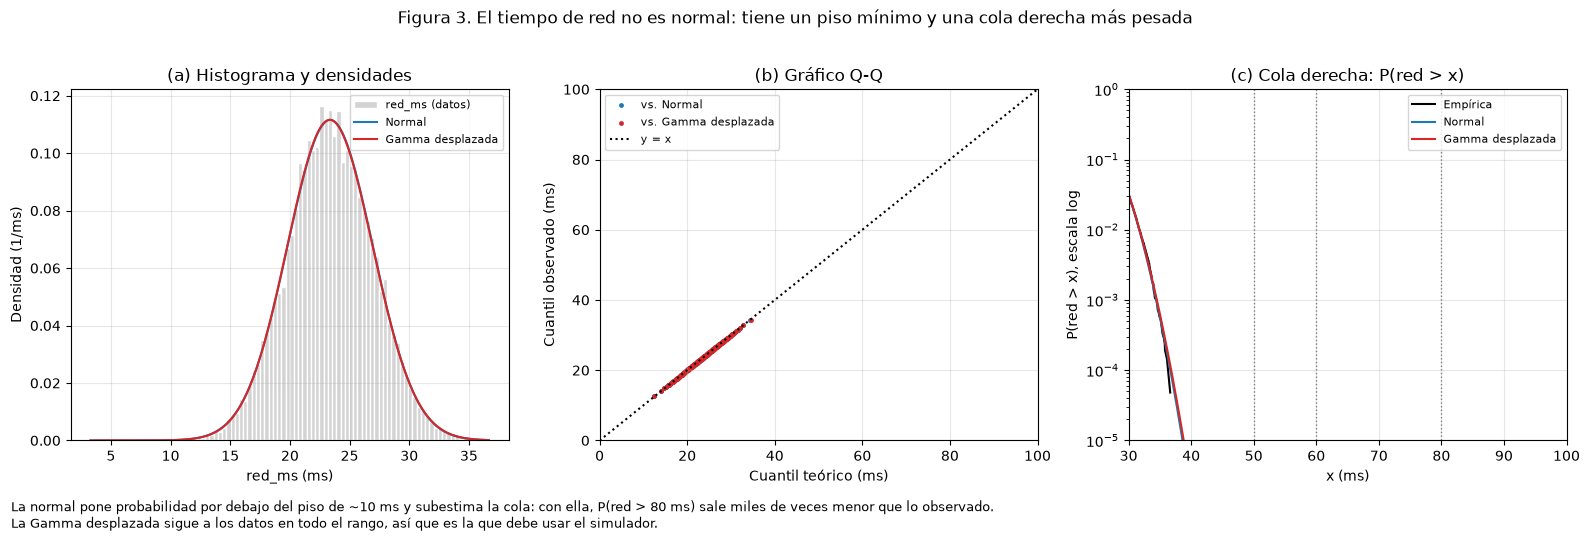

In [36]:
# Figura 3: red_ms frente al modelo normal
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
xs = np.linspace(red.min() - 5, red.max(), 500)
ax[0].hist(red, bins=80, density=True, color="lightgray", edgecolor="white", label="red_ms (datos)")
ax[0].plot(xs, stats.norm.pdf(xs, m_r, s_r), "tab:blue", label="Normal")
ax[0].plot(xs, stats.gamma.pdf(xs - loc_r, k_r, scale=th_r), "tab:red", label="Gamma desplazada")
ax[0].set(title="(a) Histograma y densidades", xlabel="red_ms (ms)", ylabel="Densidad (1/ms)")
qs = np.linspace(0.001, 0.999, 300)
ax[1].scatter(stats.norm.ppf(qs, m_r, s_r), np.quantile(red, qs), s=6, color="tab:blue", label="vs. Normal")
ax[1].scatter(loc_r + stats.gamma.ppf(qs, k_r, scale=th_r), np.quantile(red, qs), s=6, color="tab:red", label="vs. Gamma desplazada")
ax[1].plot([0, 100], [0, 100], "k:", label="y = x")
ax[1].set(title="(b) Gráfico Q-Q", xlabel="Cuantil teórico (ms)", ylabel="Cuantil observado (ms)", xlim=(0, 100), ylim=(0, 100))
xs3 = np.linspace(30, 100, 300)
ax[2].semilogy(np.sort(red), 1 - np.arange(1, n_red + 1) / (n_red + 1), color="black", label="Empírica")
ax[2].semilogy(xs3, stats.norm.sf(xs3, m_r, s_r), "tab:blue", label="Normal")
ax[2].semilogy(xs3, stats.gamma.sf(xs3 - loc_r, k_r, scale=th_r), "tab:red", label="Gamma desplazada")
for x in [50, 60, 80]:
    ax[2].axvline(x, color="gray", ls=":", lw=1)
ax[2].set(title="(c) Cola derecha: P(red > x)", xlabel="x (ms)", ylabel="P(red > x), escala log", xlim=(30, 100), ylim=(1e-5, 1))
for a in ax:
    a.legend(fontsize=8); a.grid(alpha=0.3)
fig.suptitle("Figura 3. El tiempo de red no es normal: tiene un piso mínimo y una cola derecha más pesada", y=1.02)
fig.text(0.01, -0.06, "La normal pone probabilidad por debajo del piso de ~10 ms y subestima la cola: con ella, P(red > 80 ms) sale miles de veces menor que lo observado.\n"
         "La Gamma desplazada sigue a los datos en todo el rango, así que es la que debe usar el simulador.", fontsize=9)
fig.tight_layout()
fig.savefig("figura3_red.png", dpi=150, bbox_inches="tight")
plt.show()

## C4. Tiempo total de GPU de N solicitudes consecutivas no cacheadas

Sea $T_N=\sum_{i=1}^N G_i$ y el umbral $u=N(\hat m+15)$. Equivale a que el **promedio** de las N pase de $\hat m+15$ ms. Se usan tres aproximaciones analíticas:
1. **TLC (normal):** $P\approx 1-\Phi\!\left(\frac{15\sqrt N}{\hat\sigma}\right)$.
2. **Gamma exacta:** si $G_i\sim\text{Gamma}(k,\theta)$ son independientes, $T_N\sim\text{Gamma}(Nk,\theta)$. Se usan los parámetros de momentos, que reproducen la media y la varianza observadas.
3. **Edgeworth (TLC corregido por asimetría $\gamma$):** $P\approx 1-\Phi(z)+\varphi(z)\,\frac{\gamma}{6\sqrt N}(z^2-1)$.

Se comparan con dos simulaciones: (a) remuestreo de las G observadas y (b) bloques **reales** de N solicitudes consecutivas. La (b) también prueba el supuesto de independencia.

In [37]:
m_hat, s_hat, gam_hat = G_c.mean(), G_c.std(ddof=1), stats.skew(G_c)
R_MC = 100_000

# Bloques reales de N consecutivas no cacheadas, dentro de cada tramo estable y en orden de llegada
# La suma de tiempos de solicitudes consecutivas permite contrastar la aproximación con bloques observados.
def bloques_reales(n_bloque):
    sumas = []
    for _, seg in df_estable.sort_values("t_llegada_s").groupby("segmento"):
        v = seg.loc[seg.cache_hit == 0, "gpu_ms"].dropna().to_numpy()
        nb = len(v) // n_bloque
        sumas.append(v[:nb * n_bloque].reshape(nb, n_bloque).sum(axis=1))
    return np.concatenate(sumas)

def prob_C4(n_):
    umbral = n_ * (m_hat + 15)
    z = 15 * np.sqrt(n_) / s_hat
    tlc = stats.norm.sf(z)
    gamma_exacta = stats.gamma.sf(umbral, n_ * k_mm, scale=th_mm)
    edgeworth = stats.norm.sf(z) + stats.norm.pdf(z) * gam_hat / (6 * np.sqrt(n_)) * (z**2 - 1)
    sim = (rng.choice(G_c, size=(R_MC, n_)).sum(axis=1) > umbral).mean()
    sb = bloques_reales(n_)
    return {"N": n_, "TLC": tlc, "Gamma exacta": gamma_exacta, "Edgeworth": edgeworth,
            "Simulación (remuestreo)": sim, "Bloques reales": (sb > umbral).mean(), "n bloques": len(sb)}

res_N = prob_C4(N)
sb = bloques_reales(N)
pb, pb_lo, pb_hi = ic_wilson((sb > N * (m_hat + 15)).sum(), len(sb))
ee_sim = np.sqrt(res_N["Simulación (remuestreo)"] * (1 - res_N["Simulación (remuestreo)"]) / R_MC)
print(f"N = {N}, m̂ = {m_hat:.3f} ms, umbral = {N*(m_hat+15):.1f} ms")
for k_, v in res_N.items():
    if k_ not in ("N", "n bloques"):
        print(f"  {k_:<24} {v:.5f}")
print(f"  error estándar de la simulación: {ee_sim:.5f} | bloques reales: IC {conf:.0%} Wilson [{pb_lo:.4f}, {pb_hi:.4f}] con {len(sb)} bloques")

N = 20, m̂ = 46.315 ms, umbral = 1226.3 ms
  TLC                      0.02087
  Gamma exacta             0.02858
  Edgeworth                0.03306
  Simulación (remuestreo)  0.03167
  Bloques reales           0.02958
  error estándar de la simulación: 0.00055 | bloques reales: IC 99% Wilson [0.0171, 0.0508] con 710 bloques


In [38]:
# Sensibilidad a N (10 a 20): cómo se acercan las aproximaciones al aumentar N
tabla_C4 = pd.DataFrame([res_N if n_ == N else prob_C4(n_) for n_ in range(10, 21)]).set_index("N")
for col in ["TLC", "Gamma exacta", "Edgeworth"]:
    tabla_C4[f"error {col} (%)"] = 100 * (tabla_C4[col] / tabla_C4["Simulación (remuestreo)"] - 1)
print(f"Error relativo medio frente a la simulación (N = 10 a 20): "
      f"TLC {tabla_C4['error TLC (%)'].abs().mean():.1f} % | Gamma {tabla_C4['error Gamma exacta (%)'].abs().mean():.1f} % | "
      f"Edgeworth {tabla_C4['error Edgeworth (%)'].abs().mean():.1f} %")
print(f"Asimetría real de G = {gam_hat:.3f} | asimetría que impone la Gamma de momentos = 2/√k = {2/np.sqrt(k_mm):.3f}")
tabla_C4.round(5)

Error relativo medio frente a la simulación (N = 10 a 20): TLC 23.8 % | Gamma 6.0 % | Edgeworth 6.3 %
Asimetría real de G = 2.072 | asimetría que impone la Gamma de momentos = 2/√k = 1.423


,TLC,Gamma exacta,Edgeworth,Simulación (remuestreo),Bloques reales,n bloques,error TLC (%),error Gamma exacta (%),error Edgeworth (%)
N,,,,,,,,,
10,0.07497,0.08355,0.09155,0.08389,0.08163,1421,-10.63239,-0.40722,9.13065
11,0.06552,0.07465,0.08253,0.07687,0.07204,1291,-14.76496,-2.89297,7.35662
12,0.05738,0.06680,0.07443,0.06857,0.07095,1184,-16.31938,-2.58464,8.55264
13,0.05034,0.05986,0.06717,0.06255,0.06038,1093,-19.51877,-4.30414,7.38951
14,0.04424,0.05371,0.06065,0.05673,0.04631,1015,-22.02523,-5.33158,6.90226
15,0.03892,0.04824,0.05477,0.05137,0.04863,946,-24.22862,-6.09502,6.62783
16,0.03429,0.04337,0.04949,0.04669,0.04510,887,-26.55267,-7.10547,5.99472
17,0.03025,0.03903,0.04473,0.04319,0.04192,835,-29.97003,-9.62638,3.55738
18,0.02670,0.03516,0.04043,0.03816,0.03549,789,-30.02204,-7.87288,5.95550


La simulación empírica permite comparar el error de las aproximaciones en el umbral del grupo.

In [39]:
clases = ["pequeña", "mediana", "grande"]
d1 = df_estable.dropna(subset=["tam_kb", "cache_hit"]).copy()
# La clase se decide por el tamaño en KB. Los valores iguales a cada corte pasan a la clase siguiente.
d1["clase"] = pd.cut(d1.tam_kb, [-np.inf, t1, t2, np.inf], right=False, labels=clases)
d1["cache"] = d1.cache_hit.astype(int)
conteos = pd.crosstab(d1.clase, d1.cache, margins=True, margins_name="Total")
conjunta = pd.crosstab(d1.clase, d1.cache, normalize="all", margins=True, margins_name="Total")
print(f"Clases: pequeña < {t1} KB ≤ mediana < {t2} KB ≤ grande")
print("Conteos:\n", conteos, "\n\nConjunta P(clase, caché) con sus marginales:\n", conjunta.round(4))

Clases: pequeña < 90 KB ≤ mediana < 425 KB ≤ grande
Conteos:
 cache        0     1  Total
clase                      
pequeña   1848  1863   3711
mediana   9966  4312  14278
grande    2411   413   2824
Total    14225  6588  20813 

Conjunta P(clase, caché) con sus marginales:
 cache         0       1   Total
clase                          
pequeña  0.0888  0.0895  0.1783
mediana  0.4788  0.2072  0.6860
grande   0.1158  0.0198  0.1357
Total    0.6835  0.3165  1.0000


In [40]:
# Condicionales con IC de Wilson
filas = []
for c in clases:
    sub = d1[d1.clase == c]
    p, lo, hi = ic_wilson(sub.cache.sum(), len(sub))
    filas.append({"clase": c, "n": len(sub), "P(caché | clase)": p, "IC inf": lo, "IC sup": hi})
cond_cache = pd.DataFrame(filas)
print(cond_cache.round(4).to_string(index=False))
print("\nP(clase | caché) por columnas:\n", pd.crosstab(d1.clase, d1.cache, normalize="columns").round(4))

# Prueba de independencia chi-cuadrado y V de Cramér
tab = pd.crosstab(d1.clase, d1.cache).to_numpy()
chi2, p_ind, gl, esperados = stats.chi2_contingency(tab)
V = np.sqrt(chi2 / (tab.sum() * (min(tab.shape) - 1)))
print(f"\nChi-cuadrado = {chi2:.1f}, gl = {gl}, p = {p_ind:.3g}, V de Cramér = {V:.3f}, mínimo esperado = {esperados.min():.0f}")
# IC de la diferencia P(caché|pequeña) - P(caché|grande) (Wald)
a_, b_ = d1[d1.clase == "pequeña"].cache, d1[d1.clase == "grande"].cache
dif = a_.mean() - b_.mean(); ee = np.sqrt(a_.mean()*(1-a_.mean())/len(a_) + b_.mean()*(1-b_.mean())/len(b_))
print(f"P(caché|pequeña) - P(caché|grande) = {txt_ic(dif, dif - z_conf*ee, dif + z_conf*ee, 4)}  (Wald, {conf:.0%})")
params["p_cache_clase"] = {c: float(v) for c, v in zip(cond_cache.clase, cond_cache["P(caché | clase)"])}

p_ind_tam = p_ind

  clase     n  P(caché | clase)  IC inf  IC sup
pequeña  3711            0.5020  0.4809  0.5231
mediana 14278            0.3020  0.2922  0.3120
 grande  2824            0.1462  0.1299  0.1642



P(clase | caché) por columnas:
 cache         0       1
clase                  
pequeña  0.1299  0.2828
mediana  0.7006  0.6545
grande   0.1695  0.0627

Chi-cuadrado = 982.6, gl = 2, p = 4.2e-214, V de Cramér = 0.217, mínimo esperado = 894
P(caché|pequeña) - P(caché|grande) = 0.3558  [0.3286, 0.3830]  (Wald, 99%)


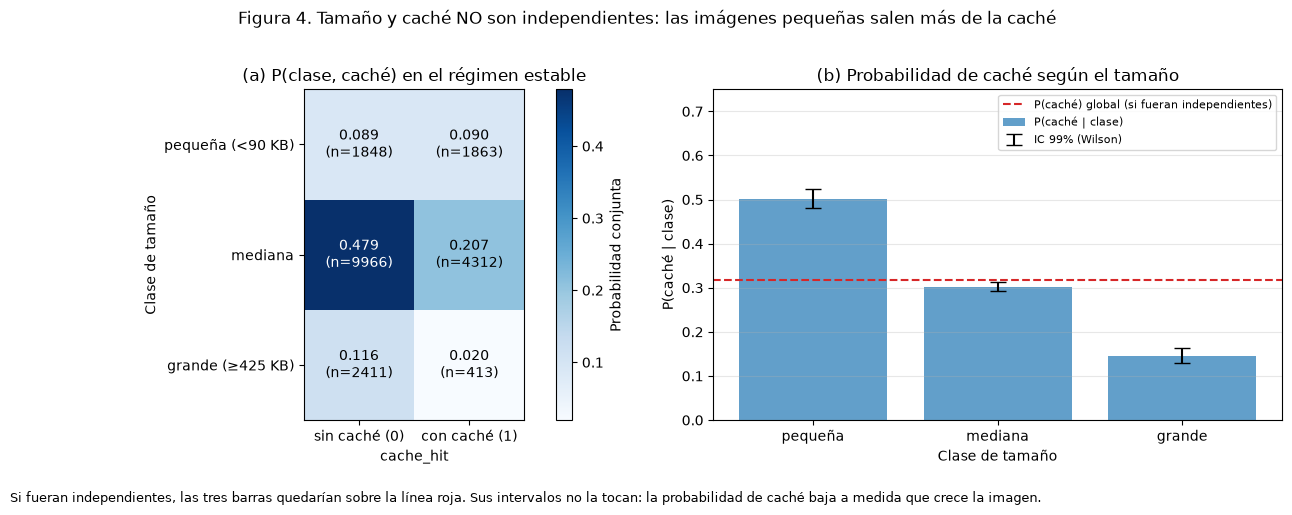

In [41]:
# Figura 4: mapa de calor de la distribución conjunta
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.1, 1]})
M = pd.crosstab(d1.clase, d1.cache, normalize="all").to_numpy()
im = ax[0].imshow(M, cmap="Blues")
for i in range(3):
    for j in range(2):
        ax[0].text(j, i, f"{M[i, j]:.3f}\n(n={tab[i, j]})", ha="center", va="center",
                   color="white" if M[i, j] > M.max() * 0.6 else "black", fontsize=10)
ax[0].set_xticks([0, 1], ["sin caché (0)", "con caché (1)"])
ax[0].set_yticks(range(3), [f"pequeña (<{t1} KB)", f"mediana", f"grande (≥{t2} KB)"])
ax[0].set(title="(a) P(clase, caché) en el régimen estable", xlabel="cache_hit", ylabel="Clase de tamaño")
fig.colorbar(im, ax=ax[0], label="Probabilidad conjunta")
ax[1].bar(clases, cond_cache["P(caché | clase)"], color="tab:blue", alpha=0.7, label="P(caché | clase)")
ax[1].errorbar(clases, cond_cache["P(caché | clase)"],
               yerr=[cond_cache["P(caché | clase)"] - cond_cache["IC inf"], cond_cache["IC sup"] - cond_cache["P(caché | clase)"]],
               fmt="none", color="black", capsize=6, label=f"IC {conf:.0%} (Wilson)")
ax[1].axhline(d1.cache.mean(), color="tab:red", ls="--", label="P(caché) global (si fueran independientes)")
ax[1].set(title="(b) Probabilidad de caché según el tamaño", xlabel="Clase de tamaño", ylabel="P(caché | clase)", ylim=(0, 0.75))
ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3, axis="y")
fig.suptitle("Figura 4. Tamaño y caché NO son independientes: las imágenes pequeñas salen más de la caché", y=1.02)
fig.text(0.01, -0.05, "Si fueran independientes, las tres barras quedarían sobre la línea roja. Sus intervalos no la tocan: "
         "la probabilidad de caché baja a medida que crece la imagen.", fontsize=9)
fig.tight_layout()
fig.savefig("figura4_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

## D2. Esperanza condicional y leyes de esperanza y varianza total

In [42]:
d2 = df_estable.dropna(subset=["tam_kb", "cache_hit", "gpu_ms"]).copy()
d2["clase"] = pd.cut(d2.tam_kb, [-np.inf, t1, t2, np.inf], right=False, labels=clases)
# E[G | clase, no caché] con IC t
filas = []
for c in clases:
    m, lo, hi = ic_media(d2.loc[(d2.clase == c) & (d2.cache_hit == 0), "gpu_ms"])
    filas.append({"clase": c, "E[G | clase, no caché] (ms)": m, "IC inf": lo, "IC sup": hi})
print(pd.DataFrame(filas).round(3).to_string(index=False))

# Estimación de E[G | tamaño] por suavizado de Nadaraya–Watson con núcleo gaussiano.
def nadaraya_watson(x, y, rejilla, ancho):
    w = np.exp(-0.5 * ((rejilla[:, None] - x[None, :]) / ancho) ** 2)
    return (w * y).sum(axis=1) / w.sum(axis=1)

x_all, g_all = d2.tam_kb.to_numpy(), d2.gpu_ms.to_numpy()
ancho_nw = 1.06 * min(x_all.std(), stats.iqr(x_all) / 1.34) * len(x_all) ** (-1 / 5)   # regla de Silverman
rejilla_nw = np.linspace(np.quantile(x_all, 0.01), np.quantile(x_all, 0.99), 150)
EG_tam = nadaraya_watson(x_all, g_all, rejilla_nw, ancho_nw)                             # incluye ceros de caché
nc2 = d2.cache_hit == 0
EG_tam_nc = nadaraya_watson(x_all[nc2], g_all[nc2], rejilla_nw, ancho_nw)
print(f"\nAncho de banda (Silverman) = {ancho_nw:.1f} KB")
print("E[G | tam_kb] en algunos tamaños (ms):")
print(pd.DataFrame({"tam_kb": rejilla_nw, "E[G|tam] (con caché)": EG_tam, "E[G|tam, no caché]": EG_tam_nc}).iloc[::25].round(2).to_string(index=False))

  clase  E[G | clase, no caché] (ms)  IC inf  IC sup
pequeña                       22.468  21.751  23.185
mediana                       41.904  41.288  42.520
 grande                       82.804  80.400  85.208



Ancho de banda (Silverman) = 22.8 KB
E[G | tam_kb] en algunos tamaños (ms):
 tam_kb  E[G|tam] (con caché)  E[G|tam, no caché]
  17.74                  9.66               19.75
 150.77                 22.89               33.13
 283.80                 34.78               48.81
 416.82                 48.05               63.88
 549.85                 66.35               77.96
 682.88                 85.85               97.16


In [43]:
# Se pondera por la proporción de solicitudes de cada grupo.
# Se usa varianza poblacional (ms²) para verificar la identidad con ddof=0.
def descomponer(df_, grupos):
    por_grupo = df_.groupby(grupos, observed=True)
    pesos = por_grupo.size() / len(df_)
    medias_ms = por_grupo.gpu_ms.mean()
    varianzas = por_grupo.gpu_ms.var(ddof=0)
    media_total_ms = df_.gpu_ms.mean()
    varianza_total = df_.gpu_ms.var(ddof=0)
    media_ponderada_ms = (pesos * medias_ms).sum()
    dentro = (pesos * varianzas).sum()
    entre = (pesos * (medias_ms - media_total_ms) ** 2).sum()
    return {
        "E[G]": media_total_ms,
        "Σ P·E[G|grupo]": media_ponderada_ms,
        "Var(G)": varianza_total,
        "E[Var(G|grupo)]": dentro,
        "Var(E[G|grupo])": entre,
        "suma": dentro + entre,
        "fracción explicada": entre / varianza_total,
    }

tabla_D2 = pd.DataFrame({
    "G (todas) | clase": descomponer(d2, "clase"),
    "G (todas) | clase y caché": descomponer(d2, ["clase", "cache_hit"]),
    "G (sin caché) | clase": descomponer(d2[nc2], "clase"),
}).T
tabla_D2.round(4)

,E[G],Σ P·E[G|grupo],Var(G),E[Var(G|grupo)],Var(E[G|grupo]),suma,fracción explicada
G (todas) | clase,31.6659,31.6659,1205.9586,920.2176,285.7410,1205.9586,0.2369
G (todas) | clase y caché,31.6659,31.6659,1205.9586,527.9117,678.0469,1205.9586,0.5622
G (sin caché) | clase,46.3147,46.3147,1085.3850,772.1261,313.2589,1085.3850,0.2886


La tabla verifica ambas identidades usando los mismos casos completos por grupos.

In [44]:
d3 = validas[(validas.cache_hit == 0) & validas.tam_kb.notna()]
x, y = d3.tam_kb.to_numpy(), d3.gpu_ms.to_numpy()
n3 = len(y)
# La primera columna estima el intercepto (ms) y la segunda, la pendiente (ms/KB).
X = np.column_stack([np.ones(n3), x])
XtX, Xty = X.T @ X, X.T @ y
beta = np.linalg.solve(XtX, Xty)                     # solución del sistema de ecuaciones normales
e = y - X @ beta
sigma2 = (e @ e) / (n3 - 2)
cov_ols = sigma2 * np.linalg.inv(XtX)
ee_ols = np.sqrt(np.diag(cov_ols))
tq = stats.t.ppf(1 - alpha / 2, n3 - 2)
R2 = 1 - (e @ e) / ((y - y.mean()) @ (y - y.mean()))
print("Números para escribir a mano:")
print(f"  n = {n3}, Σx = {x.sum():.2f}, Σx² = {(x**2).sum():.2f}, Σy = {y.sum():.2f}, Σxy = {(x*y).sum():.2f}")
print(f"  x̄ = {x.mean():.4f}, ȳ = {y.mean():.4f}, Sxx = {((x-x.mean())**2).sum():.2f}, Sxy = {((x-x.mean())*(y-y.mean())).sum():.2f}")
print("X'X =\n", XtX.round(2), "\nX'y =", Xty.round(2))
print(f"\nMCO: β0 = {txt_ic(beta[0], beta[0]-tq*ee_ols[0], beta[0]+tq*ee_ols[0], 3)} ms")
print(f"     β1 = {txt_ic(beta[1], beta[1]-tq*ee_ols[1], beta[1]+tq*ee_ols[1], 5)} ms/KB   (IC t {conf:.0%})")
print(f"     σ̂ = {np.sqrt(sigma2):.3f} ms, R² = {R2:.4f}")

Números para escribir a mano:
  n = 14213, Σx = 3712955.41, Σx² = 1426385938.41, Σy = 658271.38, Σxy = 225433347.44
  x̄ = 261.2366, ȳ = 46.3147, Sxx = 456426191.94, Sxy = 53468788.12
X'X =
 [[1.42130000e+04 3.71295541e+06]
 [3.71295541e+06 1.42638594e+09]] 
X'y = [6.58271380e+05 2.25433347e+08]

MCO: β0 = 15.712  [14.742, 16.682] ms
     β1 = 0.11715  [0.11408, 0.12021] ms/KB   (IC t 99%)
     σ̂ = 25.392 ms, R² = 0.4060


In [45]:
# Análisis de residuos
y_hat = X @ beta
# Si el tamaño explica parte del residuo al cuadrado, la dispersión del error cambia a lo largo de la recta.
def breusch_pagan(residuos, X_):
    # Regresión auxiliar de e² sobre X: LM = n·R²_aux ~ chi2(gl = columnas - 1) si hay homocedasticidad
    e2 = residuos**2
    b_aux = np.linalg.solve(X_.T @ X_, X_.T @ e2)
    r_aux = e2 - X_ @ b_aux
    R2_aux = 1 - (r_aux @ r_aux) / ((e2 - e2.mean()) @ (e2 - e2.mean()))
    LM = len(e2) * R2_aux
    return LM, stats.chi2.sf(LM, X_.shape[1] - 1)

LM, p_bp = breusch_pagan(e, X)
# Función de varianza: varianza de G por deciles de la media ajustada
dec = pd.qcut(y_hat, 10, labels=False)
fv = pd.DataFrame({"mu": y_hat, "y": y}).groupby(dec).agg(media=("y", "mean"), var=("y", "var"))
pendiente_var = np.polyfit(np.log(fv.media), np.log(fv["var"]), 1)[0]
print(f"Breusch-Pagan: LM = {LM:.1f}, p = {p_bp:.3g}  → la varianza de los residuos NO es constante")
print(f"Asimetría de los residuos = {stats.skew(e):.3f} (normal = 0)")
print(f"Pendiente de log Var(G|x) contra log E[G|x] = {pendiente_var:.2f}  (2 = coeficiente de variación constante, como una Gamma)")

Breusch-Pagan: LM = 1675.4, p = 0  → la varianza de los residuos NO es constante
Asimetría de los residuos = 1.311 (normal = 0)
Pendiente de log Var(G|x) contra log E[G|x] = 2.01  (2 = coeficiente de variación constante, como una Gamma)


In [46]:
# Corrección: mínimos cuadrados ponderados iterados con w = 1/μ², por la estructura Gamma (CV constante)
beta_w = beta.copy()
for it in range(100):
    mu = X @ beta_w
    # Los puntos con mayor variabilidad esperada reciben menos peso al volver a ajustar la recta.
    w = 1 / mu**2
    XtWX, XtWy = X.T @ (w[:, None] * X), X.T @ (w * y)
    nuevo = np.linalg.solve(XtWX, XtWy)
    if np.max(np.abs(nuevo - beta_w)) < 1e-12:
        beta_w = nuevo
        break
    beta_w = nuevo
mu = X @ beta_w; w = 1 / mu**2
phi = (w * (y - mu) ** 2).sum() / (n3 - 2)          # = CV² estimado
cov_wls = phi * np.linalg.inv(X.T @ (w[:, None] * X))
ee_wls = np.sqrt(np.diag(cov_wls))
r_std = np.sqrt(w) * (y - mu)                        # residuos ponderados
LM_w, p_bp_w = breusch_pagan(r_std, X)

# Errores robustos HC3 para MCO (otra corrección posible, solo cambia los errores estándar)
inv = np.linalg.inv(XtX)
hii = np.einsum("ij,jk,ik->i", X, inv, X)
cov_hc3 = inv @ (X.T @ ((e**2 / (1 - hii) ** 2)[:, None] * X)) @ inv
ee_hc3 = np.sqrt(np.diag(cov_hc3))

tabla_D3 = pd.DataFrame({
    "β0": [beta[0], beta[0], beta_w[0], b0_g],
    "ee β0": [ee_ols[0], ee_hc3[0], ee_wls[0], ee_cond[0]],
    "β1": [beta[1], beta[1], beta_w[1], b1_g],
    "ee β1": [ee_ols[1], ee_hc3[1], ee_wls[1], ee_cond[1]],
}, index=["MCO (supone varianza constante)", "MCO + errores robustos HC3", "MC ponderados, w = 1/μ² (corrección)", "EMV Gamma condicional (C2)"])
tabla_D3[f"IC β1 {conf:.0%}"] = [f"[{b - tq*s:.5f}, {b + tq*s:.5f}]" for b, s in zip(tabla_D3["β1"], tabla_D3["ee β1"])]
print(f"Iteraciones = {it + 1} | CV estimado = {np.sqrt(phi):.3f} | Breusch-Pagan de los residuos ponderados: LM = {LM_w:.1f}, p = {p_bp_w:.3f}")
params["beta"] = {"b0": [beta_w[0], beta_w[0] - tq*ee_wls[0], beta_w[0] + tq*ee_wls[0]],
                  "b1": [beta_w[1], beta_w[1] - tq*ee_wls[1], beta_w[1] + tq*ee_wls[1]],
                  "cv": float(np.sqrt(phi)), "metodo": "MC ponderados iterados, w = 1/mu^2"}
tabla_D3.round(5)

Iteraciones = 6 | CV estimado = 0.502 | Breusch-Pagan de los residuos ponderados: LM = 0.5, p = 0.470


,β0,ee β0,β1,ee β1,IC β1 99%
MCO (supone varianza constante),15.71176,0.37653,0.11715,0.00119,"[0.11408, 0.12021]"
MCO + errores robustos HC3,15.71176,0.42586,0.11715,0.00197,"[0.11206, 0.12223]"
"MC ponderados, w = 1/μ² (corrección)",15.90834,0.24650,0.11634,0.00130,"[0.11300, 0.11968]"
EMV Gamma condicional (C2),15.90834,0.24608,0.11634,0.00130,"[0.11300, 0.11968]"


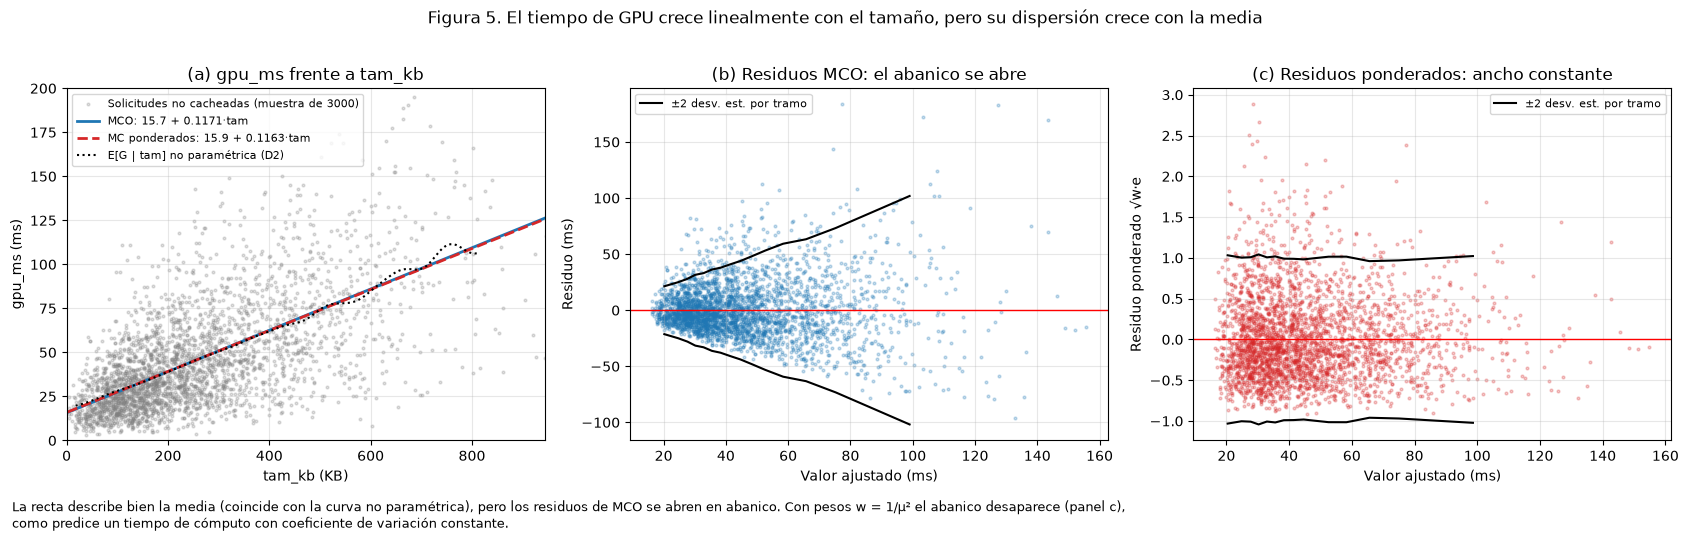

In [47]:
# Figura 5: regresión y residuos
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
idx = rng.choice(n3, size=min(3000, n3), replace=False)          # submuestra aleatoria para el gráfico de dispersión
ax[0].scatter(x[idx], y[idx], s=4, alpha=0.25, color="gray", label="Solicitudes no cacheadas (muestra de 3000)")
xs = np.linspace(x.min(), np.quantile(x, 0.995), 200)
ax[0].plot(xs, beta[0] + beta[1] * xs, "tab:blue", lw=2, label=f"MCO: {beta[0]:.1f} + {beta[1]:.4f}·tam")
ax[0].plot(xs, beta_w[0] + beta_w[1] * xs, "tab:red", lw=2, ls="--", label=f"MC ponderados: {beta_w[0]:.1f} + {beta_w[1]:.4f}·tam")
ax[0].plot(rejilla_nw, EG_tam_nc, "black", lw=1.5, ls=":", label="E[G | tam] no paramétrica (D2)")
ax[0].set(title="(a) gpu_ms frente a tam_kb", xlabel="tam_kb (KB)", ylabel="gpu_ms (ms)", xlim=(0, np.quantile(x, 0.995)), ylim=(0, 200))
ax[1].scatter(y_hat[idx], e[idx], s=4, alpha=0.25, color="tab:blue")
cort = pd.qcut(y_hat, 15, labels=False)
banda = pd.DataFrame({"f": y_hat, "e": e}).groupby(cort).agg(f=("f", "mean"), sd=("e", "std"))
ax[1].plot(banda.f, 2 * banda.sd, "k-", label="±2 desv. est. por tramo")
ax[1].plot(banda.f, -2 * banda.sd, "k-")
ax[1].axhline(0, color="red", lw=1)
ax[1].set(title="(b) Residuos MCO: el abanico se abre", xlabel="Valor ajustado (ms)", ylabel="Residuo (ms)")
ax[2].scatter(mu[idx], r_std[idx], s=4, alpha=0.25, color="tab:red")
banda_w = pd.DataFrame({"f": mu, "r": r_std}).groupby(pd.qcut(mu, 15, labels=False)).agg(f=("f", "mean"), sd=("r", "std"))
ax[2].plot(banda_w.f, 2 * banda_w.sd, "k-", label="±2 desv. est. por tramo")
ax[2].plot(banda_w.f, -2 * banda_w.sd, "k-")
ax[2].axhline(0, color="red", lw=1)
ax[2].set(title="(c) Residuos ponderados: ancho constante", xlabel="Valor ajustado (ms)", ylabel="Residuo ponderado √w·e")
for a in ax:
    a.legend(fontsize=8); a.grid(alpha=0.3)
fig.suptitle("Figura 5. El tiempo de GPU crece linealmente con el tamaño, pero su dispersión crece con la media", y=1.02)
fig.text(0.01, -0.06, "La recta describe bien la media (coincide con la curva no paramétrica), pero los residuos de MCO se abren en abanico. "
         "Con pesos w = 1/μ² el abanico desaparece (panel c),\ncomo predice un tiempo de cómputo con coeficiente de variación constante.", fontsize=9)
fig.tight_layout()
fig.savefig("figura5_regresion.png", dpi=150, bbox_inches="tight")
plt.show()

## D4. Covarianza y correlación entre tam_kb y gpu_ms (no cacheadas)

In [48]:
cov_xy = np.cov(x, y, ddof=1)[0, 1]
r_xy = np.corrcoef(x, y)[0, 1]
zf = np.arctanh(r_xy); ee_z = 1 / np.sqrt(n3 - 3)
r_lo, r_hi = np.tanh(zf - z_conf * ee_z), np.tanh(zf + z_conf * ee_z)
rho_s = stats.spearmanr(x, y)[0]
eta2_nc = tabla_D2.loc["G (sin caché) | clase", "fracción explicada"]
print(f"Cov(tam, gpu) = {cov_xy:.2f} KB·ms")
print(f"Correlación de Pearson r = {txt_ic(r_xy, r_lo, r_hi, 4)}  (IC {conf:.0%}, transformación z de Fisher)")
print(f"Correlación de Spearman = {rho_s:.4f}")
print(f"Comprobación: Cov/Var(tam) = {cov_xy/np.var(x, ddof=1):.5f} = β1 de MCO ({beta[1]:.5f})")
print(f"Comprobación: r² = {r_xy**2:.4f} = R² de MCO ({R2:.4f})")
print(f"Fracción de Var(G sin caché) que explica la CLASE (D2) = {eta2_nc:.4f}  frente a r² = {r_xy**2:.4f} con el tamaño continuo")

Cov(tam, gpu) = 3762.23 KB·ms
Correlación de Pearson r = 0.6372  [0.6242, 0.6499]  (IC 99%, transformación z de Fisher)
Correlación de Spearman = 0.6147
Comprobación: Cov/Var(tam) = 0.11715 = β1 de MCO (0.11715)
Comprobación: r² = 0.4060 = R² de MCO (0.4060)
Fracción de Var(G sin caché) que explica la CLASE (D2) = 0.2886  frente a r² = 0.4060 con el tamaño continuo


La pendiente de MCO se verifica con Cov/Var y el ajuste con el cuadrado de Pearson.

In [49]:
# Exportación de parámetros ajustados y momentos muestrales.
def a_json(o):
    if isinstance(o, dict): return {k: a_json(v) for k, v in o.items()}
    if isinstance(o, (list, tuple, np.ndarray)): return [a_json(v) for v in o]
    if isinstance(o, (np.floating, np.integer)): return o.item()
    return o
salida = {"S": S, "borrador": ES_BORRADOR, "conf": conf, "t1": t1, "t2": t2, "N": N, "params": a_json(params),
          "deducciones": a_json({"h": h_hat, "k": k_mv, "theta": th_mv, "k_mm": k_mm, "theta_mm": th_mm,
                                  "E_G_formula": E_mv, "Var_G_formula": V_mv, "E_G_muestra": G_todas.mean(), "Var_G_muestra": G_todas.var(ddof=1),
                                  "n": n3, "sum_x": x.sum(), "sum_x2": (x**2).sum(), "sum_y": y.sum(), "sum_xy": (x*y).sum(),
                                  "xbar": x.mean(), "ybar": y.mean(), "Sxx": ((x-x.mean())**2).sum(), "Sxy": ((x-x.mean())*(y-y.mean())).sum(),
                                  "b0": beta[0], "b1": beta[1], "ee_b0": ee_ols[0], "ee_b1": ee_ols[1], "sigma": np.sqrt(sigma2), "tq": tq,
                                  "b0_w": beta_w[0], "b1_w": beta_w[1], "cv": np.sqrt(phi)})}

# Parte E — Monitoreo y decisión de alertas
Usa SOLO monitoreo.csv (minuto, D1, D2, incidente) y los parámetros del grupo:
  rng, conf, alpha, pi_prod (prevalencia en producción), kmax.
ic_wilson() viene de la celda de funciones compartidas (Parte F); si no, se define aquí.

In [50]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Inicialización de los parámetros y la tabla de monitoreo.
# -----------------------------------------------------

from pathlib import Path
# Ruta de la telemetría de monitoreo.
ARCHIVO = next(p / "monitoreo.csv" for p in [Path("."), Path("/content")] if (p / "monitoreo.csv").exists())
print("Leyendo:", ARCHIVO)
mon = pd.read_csv(ARCHIVO)
mon["D1_y_D2"] = (mon["D1"] & mon["D2"]).astype(int)
mon["D1_o_D2"] = (mon["D1"] | mon["D2"]).astype(int)
reglas = ["D1", "D2", "D1_y_D2", "D1_o_D2"]
inc = mon["incidente"] == 1
print(f"Minutos: {len(mon)}, con incidente: {inc.sum()} ({inc.mean():.3%})  "
      f"<- prevalencia del entorno de PRUEBAS, no de producción (π = {pi_prod})")

Leyendo: monitoreo.csv
Minutos: 6000, con incidente: 538 (8.967%)  <- prevalencia del entorno de PRUEBAS, no de producción (π = 0.009)


## E1. Sensibilidad y tasa de falsos positivos (IC de Wilson)
Sensibilidad = P(alerta | incidente)      Tasa de FP = P(alerta | sin incidente)

In [51]:
filas = []
# La sensibilidad usa como denominador los minutos con incidente; los falsos positivos usan los minutos sin incidente.
for regla in reglas:
    x_s, n_s = mon.loc[inc, regla].sum(), inc.sum()
    x_f, n_f = mon.loc[~inc, regla].sum(), (~inc).sum()
    s, sl, su = ic_wilson(x_s, n_s)
    f, fl, fu = ic_wilson(x_f, n_f)
    filas.append({"regla": regla, "x_sens": x_s, "n_sens": n_s, "x_fp": x_f, "n_fp": n_f,
                  "sens": s, "sens_lo": sl, "sens_hi": su, "fpr": f, "fpr_lo": fl, "fpr_hi": fu})
e1 = pd.DataFrame(filas).set_index("regla")
print(e1[["sens", "sens_lo", "sens_hi", "fpr", "fpr_lo", "fpr_hi"]].round(4))

           sens  sens_lo  sens_hi     fpr  fpr_lo  fpr_hi
regla                                                    
D1       0.9052   0.8676   0.9330  0.0092  0.0064  0.0131
D2       0.7565   0.7059   0.8009  0.0077  0.0052  0.0114
D1_y_D2  0.6877   0.6342   0.7366  0.0022  0.0011  0.0045
D1_o_D2  0.9740   0.9497   0.9867  0.0146  0.0110  0.0195


## E2. P(incidente real | alerta) en producción — Teorema de Bayes
  VPP = sens·π / (sens·π + FPR·(1−π))
Con π de producción (pequeña) el VPP es mucho menor que en monitoreo.csv, porque ahí
los incidentes se inyectaron a propósito y son mucho más frecuentes (efecto tasa base).
IC del VPP: propagamos la incertidumbre de sens y FPR con Montecarlo, sorteándolas de
sus distribuciones Beta (Jeffreys: Beta(x+½, n−x+½)).

In [52]:
# Se divide la probabilidad de una alerta verdadera por la de cualquier alerta.
def vpp(sens, fpr, prev):
    alerta_verdadera = sens * prev
    alerta_falsa = fpr * (1 - prev)
    prob_alerta = alerta_verdadera + alerta_falsa
    return alerta_verdadera / prob_alerta


M = 20_000
prev_pruebas = inc.mean()
e2 = []
for regla, f in e1.iterrows():
    s_sim = rng.beta(f.x_sens + 0.5, f.n_sens - f.x_sens + 0.5, M)
    f_sim = rng.beta(f.x_fp + 0.5, f.n_fp - f.x_fp + 0.5, M)
    v_sim = vpp(s_sim, f_sim, pi_prod)
    lo, hi = np.quantile(v_sim, [alpha / 2, 1 - alpha / 2])
    e2.append({"regla": regla, "VPP_produccion": vpp(f.sens, f.fpr, pi_prod),
               "lo": lo, "hi": hi, "VPP_en_monitoreo.csv": vpp(f.sens, f.fpr, prev_pruebas)})
e2 = pd.DataFrame(e2).set_index("regla")
print(e2.round(4))

         VPP_produccion      lo      hi  VPP_en_monitoreo.csv
regla                                                        
D1               0.4731  0.3885  0.5699                0.9069
D2               0.4719  0.3781  0.5741                0.9065
D1_y_D2          0.7398  0.5937  0.8666                0.9686
D1_o_D2          0.3765  0.3132  0.4488                0.8675


## E3. ¿D1 y D2 son condicionalmente independientes dado el estado?
Dentro de cada estado (con / sin incidente) armamos la tabla 2x2 D1×D2 y probamos
independencia (Fisher exacta; chi² si las celdas son grandes).
Si fueran independientes: P(D1=1, D2=1 | estado) = P(D1=1 | estado)·P(D2=1 | estado).
Efecto en E2: comparamos el VPP de "D1 y D2" medido directamente con el que daría
suponer independencia.

In [53]:
for nombre, mask in [("con incidente", inc), ("sin incidente", ~inc)]:
    sub = mon[mask]
    tabla = pd.crosstab(sub["D1"], sub["D2"]).reindex(index=[0, 1], columns=[0, 1], fill_value=0)
    odds, p_f = stats.fisher_exact(tabla.values)
    p11 = (sub["D1"] & sub["D2"]).mean()
    p_ind = sub["D1"].mean() * sub["D2"].mean()
    print(f"[{nombre}] tabla D1×D2:\n{tabla}\n  P(ambas)={p11:.4f}  producto={p_ind:.4f}  "
          f"odds ratio={odds:.2f}  Fisher p={p_f:.4g}")

s_ind = e1.loc["D1", "sens"] * e1.loc["D2", "sens"]
f_ind = e1.loc["D1", "fpr"] * e1.loc["D2", "fpr"]
print(f"\nVPP de 'D1 y D2' en producción: real={e2.loc['D1_y_D2','VPP_produccion']:.4f}  "
      f"suponiendo independencia={vpp(s_ind, f_ind, pi_prod):.4f}")
# La dependencia positiva aumenta la frecuencia de falsos positivos conjuntos
# respecto al producto de las tasas marginales.

[con incidente] tabla D1×D2:
D2    0    1
D1          
0    14   37
1   117  370
  P(ambas)=0.6877  producto=0.6848  odds ratio=1.20  Fisher p=0.6079
[sin incidente] tabla D1×D2:
D2     0   1
D1          
0   5382  30
1     38  12
  P(ambas)=0.0022  producto=0.0001  odds ratio=56.65  Fisher p=7.603e-16

VPP de 'D1 y D2' en producción: real=0.7398  suponiendo independencia=0.9888


## E4. Falsas alarmas por día: P(X <= kmax) >= 0.90
En un día hay 1440 minutos; los minutos sin incidente son ≈ 1440·(1−π).
Si cada uno da falsa alarma con prob. FPR, independiente:  X ~ Binomial(n0, FPR).
Propagación de incertidumbre: sorteamos FPR de su Beta y calculamos P(X <= kmax) en cada
sorteo. Criterio conservador: la regla cumple si el percentil alpha de esa probabilidad
(el peor caso razonable) sigue siendo >= 0.90.

kmax = 5, minutos sin incidente por día = 1427
         FA_esperadas_dia  P(X<=kmax) puntual  P(X<=kmax) peor caso  P(cumple)    sens  cumple
regla                                                                                         
D1                13.0630              0.0101                0.0003     0.0000  0.9052   False
D2                10.9729              0.0376                0.0021     0.0000  0.7565   False
D1_y_D2            3.1351              0.9021                0.4714     0.4948  0.6877   False
D1_o_D2           20.9008              0.0000                0.0000     0.0000  0.9740   False
         FA_esperadas_dia  P(X<=kmax) puntual  P(X<=kmax) peor caso  P(cumple)    sens  cumple
regla                                                                                         
D1                13.0630              0.0101                0.0003     0.0000  0.9052   False
D2                10.9729              0.0376                0.0021     0.0000  0.7565   False
D1_

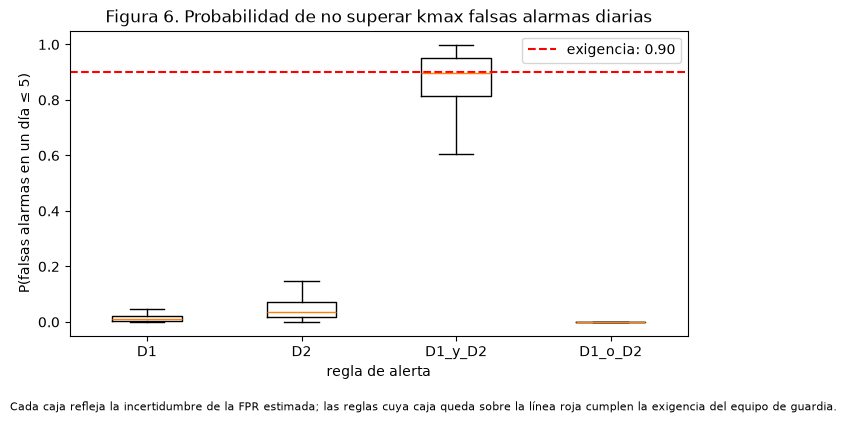

In [54]:
n0 = int(round(1440 * (1 - pi_prod)))
e4 = []
dist_prob = {}
for regla, f in e1.iterrows():
    # Con pocos falsos positivos, la tasa real es incierta. Cada tasa simulada produce una probabilidad diaria distinta.
    f_sim = rng.beta(f.x_fp + 0.5, f.n_fp - f.x_fp + 0.5, M)
    prob_sim = stats.binom.cdf(kmax, n0, f_sim)
    dist_prob[regla] = prob_sim
    e4.append({"regla": regla, "FA_esperadas_dia": n0 * f.fpr,
               "P(X<=kmax) puntual": stats.binom.cdf(kmax, n0, f.fpr),
               "P(X<=kmax) peor caso": np.quantile(prob_sim, alpha),
               "P(cumple)": np.mean(prob_sim >= 0.90),
               "sens": f.sens})
e4 = pd.DataFrame(e4).set_index("regla")
e4["cumple"] = e4["P(X<=kmax) peor caso"] >= 0.90
print(f"kmax = {kmax}, minutos sin incidente por día = {n0}")
print(e4.round(4))

candidatas = e4[e4["cumple"]]
pd.set_option("display.width", 200)
print(e4.round(4).to_string())
if len(candidatas):
    recomendada = candidatas["sens"].idxmax()
    print(f"Regla recomendada (cumple y detecta más incidentes): {recomendada}")
else:
    # Si el conjunto de reglas admisibles está vacío, se selecciona la de mayor probabilidad puntual.
    recomendada = e4["P(X<=kmax) puntual"].idxmax()
    print(f"NINGUNA regla cumple la exigencia. La más cercana es {recomendada} "
          f"(P = {e4.loc[recomendada, 'P(X<=kmax) puntual']:.3f}); hay que reportarlo así.")
params["regla_alerta"] = recomendada

# Figura 6
fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot([dist_prob[r] for r in reglas], showfliers=False)
ax.set_xticks(range(1, len(reglas) + 1), reglas)
ax.axhline(0.90, color="red", ls="--", label="exigencia: 0.90")
ax.set_ylabel(f"P(falsas alarmas en un día ≤ {kmax})")
ax.set_xlabel("regla de alerta")
ax.set_title("Figura 6. Probabilidad de no superar kmax falsas alarmas diarias")
ax.legend()
plt.figtext(0.01, -0.04, "Cada caja refleja la incertidumbre de la FPR estimada; las reglas cuya "
            "caja queda sobre la línea roja cumplen la exigencia del equipo de guardia.", fontsize=8)
plt.tight_layout()
plt.savefig("figura6_alertas.png", dpi=150, bbox_inches="tight")
plt.show()
# El modelo binomial diario supone independencia entre minutos.
# La correlación temporal positiva puede aumentar la varianza del conteo diario.

# Parte F — Inferencia, distribuciones muestrales y comparación de versiones
Lee de la primera celda: S, rng, tau, conf, alpha.   De la Parte A: limpiar(), df_estable.
Escribe en params: params["metodo_ic_prop"] y los resultados de F3/F6.
Librerías permitidas: numpy, scipy, pandas, matplotlib.

In [55]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Inicialización de los parámetros de inferencia.
# -------------------------------------------------------------------------------

z = stats.norm.ppf(1 - alpha / 2)

## Funciones de intervalos (las compartimos con E y G)

In [56]:
def ic_media_t(x, conf=conf):
    """IC t clásico para la media: x̄ ± t * s/√n. Supone datos independientes."""
    x = np.asarray(x, float)
    n = x.size
    m, s = x.mean(), x.std(ddof=1)
    t = stats.t.ppf(1 - (1 - conf) / 2, n - 1)
    return m, m - t * s / np.sqrt(n), m + t * s / np.sqrt(n)


def ic_wald(x, n, conf=conf):
    """IC de Wald para una proporción: p̂ ± z √(p̂(1-p̂)/n)."""
    zz = stats.norm.ppf(1 - (1 - conf) / 2)
    p = x / n
    se = np.sqrt(p * (1 - p) / n)
    return p, p - zz * se, p + zz * se


def ic_wilson(x, n, conf=conf):
    """IC de Wilson (score) para una proporción. Funciona bien con p pequeña."""
    zz = stats.norm.ppf(1 - (1 - conf) / 2)
    p = x / n
    centro = (p + zz**2 / (2 * n)) / (1 + zz**2 / n)
    semi = zz * np.sqrt(p * (1 - p) / n + zz**2 / (4 * n**2)) / (1 + zz**2 / n)
    return p, centro - semi, centro + semi


def ic_dif_newcombe(x1, n1, x2, n2, conf=conf):
    """IC para p2 - p1 (método híbrido de Newcombe, construido con dos Wilson)."""
    p1, l1, u1 = ic_wilson(x1, n1, conf)
    p2, l2, u2 = ic_wilson(x2, n2, conf)
    d = p2 - p1
    return d, d - np.sqrt((p2 - l2) ** 2 + (u1 - p1) ** 2), d + np.sqrt((u2 - p2) ** 2 + (p1 - l1) ** 2)


def ic_dif_welch(xA, xB, conf=conf):
    """IC para media(B) - media(A) con varianzas distintas (Welch)."""
    xA, xB = np.asarray(xA, float), np.asarray(xB, float)
    vA, vB = xA.var(ddof=1) / xA.size, xB.var(ddof=1) / xB.size
    gl = (vA + vB) ** 2 / (vA**2 / (xA.size - 1) + vB**2 / (xB.size - 1))
    d = xB.mean() - xA.mean()
    t = stats.t.ppf(1 - (1 - conf) / 2, gl)
    return d, d - t * np.sqrt(vA + vB), d + t * np.sqrt(vA + vB)

## F1. Distribución muestral de la media de la latencia
**Población:** las latencias del régimen estable (después de la limpieza). Justificación:
es la mejor representación disponible del sistema en operación normal; muestreamos
con reemplazo (equivale a una población infinita con esa distribución).
Para cada n sacamos M muestras y miramos la forma de la distribución de x̄.
**Cobertura efectiva:** % de veces que x̄ ± z s/√n contiene la media verdadera.

Población: media=58.30 ms, sd=38.39, asimetría=1.67, curtosis exceso=4.69


      n   sd(x̄)     σ/√n  asimetría  curtosis_exceso  cobertura
0     5  16.9277  17.1701     0.7048           0.7231     0.9077
1    30   6.9996   7.0097     0.2953           0.1948     0.9709
2   200   2.7369   2.7148     0.0822           0.0739     0.9854
3  2000   0.8651   0.8585     0.0482           0.0031     0.9885
n=    5  cobertura=0.9025
n=   10  cobertura=0.9367
n=   15  cobertura=0.9555
n=   20  cobertura=0.9654
n=   30  cobertura=0.9723
n=   40  cobertura=0.9746
n=   50  cobertura=0.9783
n=   75  cobertura=0.9801
Menor n con cobertura >= 0.98: n = 75


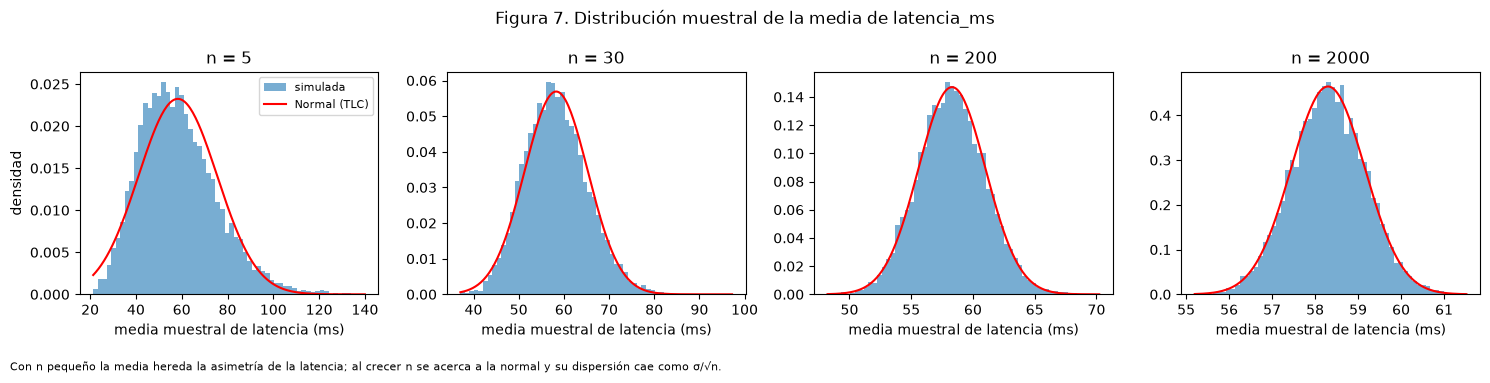

In [57]:
poblacion = df_estable["latencia_ms"].dropna().to_numpy()   # NaN = campo dañado (Parte A)
mu_pob, sd_pob = poblacion.mean(), poblacion.std()
print(f"Población: media={mu_pob:.2f} ms, sd={sd_pob:.2f}, "
      f"asimetría={stats.skew(poblacion):.2f}, curtosis exceso={stats.kurtosis(poblacion):.2f}")

M = 10_000


def medias_y_cobertura(n, M=M, bloque=1000):
    """Devuelve las M medias muestrales y la cobertura del IC normal (z)."""
    medias, cubre = [], 0
    for _ in range(M // bloque):                       # remuestreo por lotes para limitar la memoria utilizada
        muestras = rng.choice(poblacion, size=(bloque, n), replace=True)
        xb = muestras.mean(axis=1)
        s = muestras.std(axis=1, ddof=1)
        cubre += np.sum(np.abs(xb - mu_pob) <= z * s / np.sqrt(n))
        medias.append(xb)
    return np.concatenate(medias), cubre / M


tabla_f1 = []
medias_por_n = {}
for n in [5, 30, 200, 2000]:
    xb, cob = medias_y_cobertura(n)
    medias_por_n[n] = xb
    tabla_f1.append({"n": n, "sd(x̄)": xb.std(), "σ/√n": sd_pob / np.sqrt(n),
                     "asimetría": stats.skew(xb), "curtosis_exceso": stats.kurtosis(xb),
                     "cobertura": cob})
print(pd.DataFrame(tabla_f1).round(4))

# Menor n con cobertura >= conf - 0.01
objetivo = conf - 0.01
n_min = None
for n in [5, 10, 15, 20, 30, 40, 50, 75, 100, 150, 200, 300, 500, 1000, 2000]:
    _, cob = medias_y_cobertura(n)
    print(f"n={n:5d}  cobertura={cob:.4f}")
    if cob >= objetivo:
        n_min = n
        break
print(f"Menor n con cobertura >= {objetivo:.2f}: n = {n_min}")

# Figura 7
fig, axs = plt.subplots(1, 4, figsize=(15, 3.5))
for ax, n in zip(axs, [5, 30, 200, 2000]):
    xb = medias_por_n[n]
    ax.hist(xb, bins=60, density=True, alpha=0.6, label="simulada")
    xs = np.linspace(xb.min(), xb.max(), 200)
    ax.plot(xs, stats.norm.pdf(xs, mu_pob, sd_pob / np.sqrt(n)), "r", label="Normal (TLC)")
    ax.set_title(f"n = {n}")
    ax.set_xlabel("media muestral de latencia (ms)")
axs[0].set_ylabel("densidad")
axs[0].legend(fontsize=8)
fig.suptitle("Figura 7. Distribución muestral de la media de latencia_ms")
plt.figtext(0.01, -0.05, "Con n pequeño la media hereda la asimetría de la latencia; "
            "al crecer n se acerca a la normal y su dispersión cae como σ/√n.", fontsize=8)
plt.tight_layout()
plt.savefig("figura7_tlc.png", dpi=150, bbox_inches="tight")
plt.show()

## F2. IC para la latencia media y revisión de supuestos
El IC t clásico supone (1) observaciones independientes y (2) normalidad o n grande.
(2) se cumple por el TLC (F1). (1) probablemente NO: hay cola, y si una solicitud espera,
la siguiente también tiende a esperar -> latencias autocorrelacionadas.
Corrección: **medias por lotes** (batch means). Se ordena en el tiempo, se parte en k
lotes consecutivos, y el IC se hace con las k medias (casi independientes entre sí).

In [58]:
# Las medias por lotes se calculan dentro de cada tramo estable.
# El pico se excluye antes de agrupar las observaciones.
# Las solicitudes consecutivas pueden compartir la misma cola. El intervalo por lotes conserva parte de esa dependencia.
lat_t = df_estable.sort_values("t_llegada_s")["latencia_ms"].dropna().to_numpy()

m_cl, lo_cl, hi_cl = ic_media_t(lat_t)


def autocorr(x, lag):
    x = x - x.mean()
    return np.sum(x[:-lag] * x[lag:]) / np.sum(x * x)


acf = {k: autocorr(lat_t, k) for k in [1, 2, 5, 10, 50]}
banda = z / np.sqrt(lat_t.size)          # banda aprox. si no hubiera autocorrelación
print("Autocorrelación:", {k: round(v, 3) for k, v in acf.items()}, f" banda ±{banda:.3f}")

k_lotes = 30
lotes = []
for _, tramo in df_estable.sort_values("t_llegada_s").groupby("segmento"):
    x = tramo["latencia_ms"].dropna().to_numpy()
    k_tramo = max(2, round(k_lotes * len(x) / len(lat_t)))   # lotes proporcionales al tramo
    lotes += np.array_split(x, k_tramo)
medias_lote = np.array([b.mean() for b in lotes])
print(f"Autocorrelación lag-1 entre medias de lote: {autocorr(medias_lote, 1):.3f}")
m_bm, lo_bm, hi_bm = ic_media_t(medias_lote)

print(f"IC clásico  {conf:.0%}: {m_cl:.2f} [{lo_cl:.2f}, {hi_cl:.2f}]  ancho={hi_cl-lo_cl:.2f}")
print(f"IC por lotes {conf:.0%}: {m_bm:.2f} [{lo_bm:.2f}, {hi_bm:.2f}]  ancho={hi_bm-lo_bm:.2f}")
print(f"El IC corregido es {(hi_bm-lo_bm)/(hi_cl-lo_cl):.2f} veces más ancho")

Autocorrelación: {1: np.float64(0.092), 2: np.float64(0.091), 5: np.float64(0.042), 10: np.float64(0.002), 50: np.float64(0.004)}  banda ±0.018
Autocorrelación lag-1 entre medias de lote: 0.114
IC clásico  99%: 58.30 [57.61, 58.99]  ancho=1.37
IC por lotes 99%: 58.30 [57.19, 59.41]  ancho=2.23
El IC corregido es 1.62 veces más ancho


## F3. ¿La versión B es mejor que la A?
Tres comparaciones, todas como B − A:
  (i)   tiempo medio de GPU de solicitudes no cacheadas   -> Welch
  (ii)  P(intentos > 1)                                    -> Newcombe (Wilson)
  (iii) P(latencia > tau)                                  -> Newcombe (Wilson)
Como se reportan juntas, usamos **Bonferroni**: cada IC al nivel 1 - alpha/3, para que
las tres a la vez tengan confianza conjunta >= 1 - alpha.

In [59]:
A = df_estable[df_estable["version"] == "A"]
B_ = df_estable[df_estable["version"] == "B"]

# Balance de las covariables entre las versiones A y B.
def dif_estandarizada(a, b):
    return (b.mean() - a.mean()) / np.sqrt((a.var() + b.var()) / 2)

print("Balance entre versiones (|dif. estandarizada| < 0.1 = comparables):")
for col in ["tam_kb", "red_ms", "cache_hit"]:
    print(f"  {col:10s} SMD = {dif_estandarizada(A[col], B_[col]):+.3f}")
x_prop = stats.binomtest(len(B_), len(df_estable), 0.5)
print(f"  Proporción asignada a B = {len(B_)/len(df_estable):.3f} (p-valor vs 0.5: {x_prop.pvalue:.3f})")

# Bonferroni distribuye el error familiar entre los tres intervalos de la comparación A/B.
conf_bonf = 1 - alpha / 3
gA = A.loc[A["cache_hit"] == 0, "gpu_ms"].dropna()
gB = B_.loc[B_["cache_hit"] == 0, "gpu_ms"].dropna()
A_i, A_l = A.dropna(subset=["intentos"]), A.dropna(subset=["latencia_ms"])      # para (ii) y (iii)
B_i, B_l = B_.dropna(subset=["intentos"]), B_.dropna(subset=["latencia_ms"])
f3 = {
    "(i) GPU media (ms)": ic_dif_welch(gA, gB, conf_bonf),
    "(ii) P(intentos>1)": ic_dif_newcombe((A_i["intentos"] > 1).sum(), len(A_i),
                                         (B_i["intentos"] > 1).sum(), len(B_i), conf_bonf),
    "(iii) P(L>tau)": ic_dif_newcombe((A_l["latencia_ms"] > tau).sum(), len(A_l),
                                     (B_l["latencia_ms"] > tau).sum(), len(B_l), conf_bonf),
}
print(f"\nDiferencias B − A, IC Bonferroni (cada uno al {conf_bonf:.4f}):")
for nombre, (d, lo, hi) in f3.items():
    veredicto = "B menor (mejor)" if hi < 0 else ("B mayor (peor)" if lo > 0 else "sin diferencia clara")
    print(f"  {nombre:20s} {d:+.4f}  [{lo:+.4f}, {hi:+.4f}]  -> {veredicto}")
params["F3"] = f3
# La regla de adopción requiere al menos una mejora con intervalo negativo
# y ningún intervalo que indique un deterioro.

Balance entre versiones (|dif. estandarizada| < 0.1 = comparables):
  tam_kb     SMD = +0.034
  red_ms     SMD = +0.002
  cache_hit  SMD = -0.028
  Proporción asignada a B = 0.498 (p-valor vs 0.5: 0.647)

Diferencias B − A, IC Bonferroni (cada uno al 0.9967):
  (i) GPU media (ms)   -3.0080  [-4.6295, -1.3866]  -> B menor (mejor)
  (ii) P(intentos>1)   -0.0012  [-0.0154, +0.0130]  -> sin diferencia clara
  (iii) P(L>tau)       -0.0003  [-0.0022, +0.0016]  -> sin diferencia clara


## F4. Wald vs. Wilson: cobertura real con >= 10^4 réplicas
Para cada (n, p verdadera) generamos 10^4 conteos X ~ Binomial(n, p) y miramos qué
porcentaje de intervalos contiene p. Lo nominal es conf.

       Wald                      Wilson                     
n       10     30     100    500    10     30     100    500
p                                                           
0.01  0.096  0.264  0.643  0.961  0.904  0.964  0.981  0.986
0.02  0.180  0.452  0.872  0.974  0.986  0.978  0.984  0.993
0.05  0.394  0.783  0.960  0.979  0.989  0.986  0.988  0.990
0.10  0.653  0.957  0.974  0.984  0.987  0.991  0.988  0.991
0.30  0.960  0.969  0.986  0.990  0.988  0.990  0.988  0.990
0.50  0.979  0.982  0.987  0.989  0.998  0.995  0.987  0.989


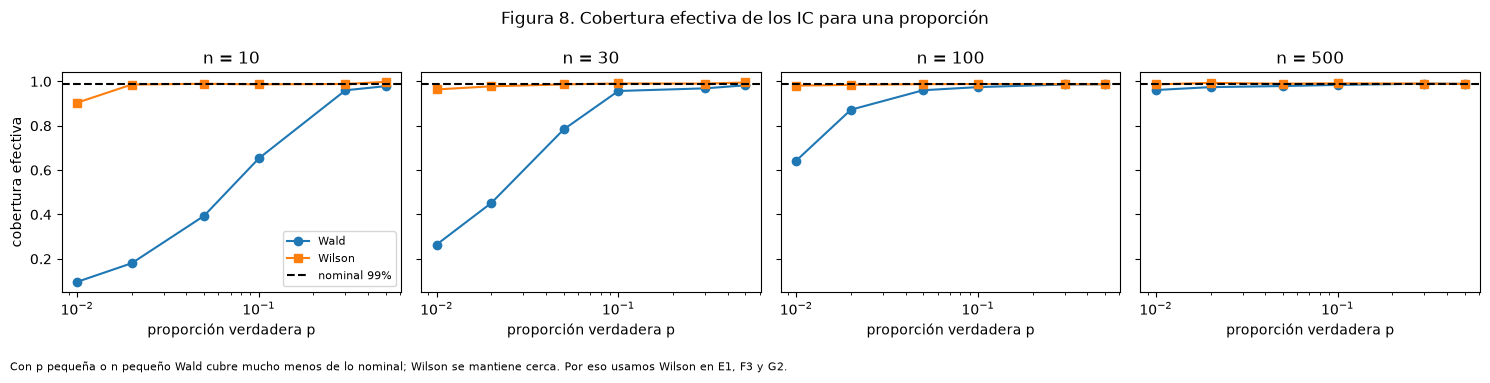

In [60]:
R4 = 10_000
ns = [10, 30, 100, 500]
ps = [0.01, 0.02, 0.05, 0.10, 0.30, 0.50]
filas = []
for n in ns:
    for p in ps:
        X = rng.binomial(n, p, R4)
        _, inferior_wald, superior_wald = ic_wald(X, n)
        _, inferior_wilson, superior_wilson = ic_wilson(X, n)
        # Se mide la fracción de intervalos que contienen la proporción verdadera.
        cubre_wald = (inferior_wald <= p) & (p <= superior_wald)
        cubre_wilson = (inferior_wilson <= p) & (p <= superior_wilson)
        filas.append({
            "n": n,
            "p": p,
            "Wald": cubre_wald.mean(),
            "Wilson": cubre_wilson.mean(),
        })
tabla_f4 = pd.DataFrame(filas)
print(tabla_f4.pivot(index="p", columns="n", values=["Wald", "Wilson"]).round(3))

fig, axs = plt.subplots(1, len(ns), figsize=(15, 3.5), sharey=True)
for ax, n in zip(axs, ns):
    t = tabla_f4[tabla_f4["n"] == n]
    ax.plot(t["p"], t["Wald"], "o-", label="Wald")
    ax.plot(t["p"], t["Wilson"], "s-", label="Wilson")
    ax.axhline(conf, color="k", ls="--", label=f"nominal {conf:.0%}")
    ax.set_xscale("log")
    ax.set_title(f"n = {n}")
    ax.set_xlabel("proporción verdadera p")
axs[0].set_ylabel("cobertura efectiva")
axs[0].legend(fontsize=8)
fig.suptitle("Figura 8. Cobertura efectiva de los IC para una proporción")
plt.figtext(0.01, -0.05, "Con p pequeña o n pequeño Wald cubre mucho menos de lo nominal; "
            "Wilson se mantiene cerca. Por eso usamos Wilson en E1, F3 y G2.", fontsize=8)
plt.tight_layout()
plt.savefig("figura8_wald_wilson.png", dpi=150, bbox_inches="tight")
plt.show()
params["metodo_ic_prop"] = "wilson"

## F5. Tamaño de muestra por versión para semiancho <= 1 ms en F3(i)
Semiancho = z * sqrt(sA²/n + sB²/n) <= 1  =>  n >= z² (sA² + sB²) / 1²
(z con el mismo nivel que F3(i), o sea Bonferroni 1 - alpha/3). Deducción a mano.

In [61]:
z_bonf = stats.norm.ppf(1 - (alpha / 3) / 2)
sA2, sB2 = gA.var(ddof=1), gB.var(ddof=1)
# El semiancho debe ser de 1 ms como máximo en el cálculo de planificación. Se redondea hacia arriba por versión.
n_req = int(np.ceil(z_bonf**2 * (sA2 + sB2) / 1.0**2))
print(f"sA² = {sA2:.1f}, sB² = {sB2:.1f}, z = {z_bonf:.4f}  ->  n por versión = {n_req}")

# Cada réplica remuestrea n_req observaciones por versión y calcula el semiancho del intervalo.
semis = []
for _ in range(2000):
    a = rng.choice(gA.to_numpy(), n_req)
    b = rng.choice(gB.to_numpy(), n_req)
    d, lo, hi = ic_dif_welch(a, b, conf_bonf)
    semis.append((hi - lo) / 2)
semis = np.array(semis)
print(f"Semiancho simulado: mediana={np.median(semis):.3f} ms, "
      f"P(semiancho <= 1) = {np.mean(semis <= 1):.3f}")

sA² = 1135.9, sB² = 1031.3, z = 2.9352  ->  n por versión = 18672


Semiancho simulado: mediana=1.000 ms, P(semiancho <= 1) = 0.516


## F6. Validación con solicitudes_validacion.csv (solo se usa aquí)
Aplicamos la MISMA limpieza y comparamos cada parámetro con su IC original.
Si el valor de validación cae fuera del IC original (o la prueba de dos muestras rechaza),
el parámetro cambió.

In [62]:
# F6 es el único acceso al CSV de validación. Se usa exactamente la limpieza de A1.
# La auditoría de la segunda ventana reutiliza la función de limpieza de A1.
df_val = limpiar(pd.read_csv(Path("solicitudes_validacion.csv")))
tv = df_val.t_llegada_s.to_numpy()
cuentas_val = np.histogram(tv,bins=np.arange(0,1200+10,10))[0]
d_val = ((cuentas_val-cuentas_val.mean())**2/cuentas_val.mean()).sum()
p_disp_val = stats.chi2.sf(d_val,len(cuentas_val)-1)
print(f"Dispersión por 10 s p={p_disp_val:.4f}. Ventana de validación completa de 1200 s.")
def f6_datos(d, dur):
    gpu = d.loc[d.cache_hit.eq(0),"gpu_ms"].dropna()
    red = d.red_ms.dropna()
    lat = d.latencia_ms.dropna()
    intentos = d.intentos.dropna()
    cache_d = d.cache_hit.dropna()
    return {"tasa":len(d)/dur,"gpu":gpu,"red":red,"lat":lat,"reintentos":intentos.gt(1),
            "cache":cache_d.eq(1),"violaciones":lat.gt(tau)}
ve, vv = f6_datos(df_estable,dur_estable), f6_datos(df_val,1200)
f6_cambios = {}
for metrica in ["gpu","red","lat"]:
    a_f6,b_f6 = ve[metrica],vv[metrica]
    f6_cambios[metrica] = ic_dif_welch(a_f6,b_f6,conf)
    print(metrica, "cambio (IC Welch)",f6_cambios[metrica],"p KS",stats.ks_2samp(a_f6,b_f6).pvalue)
for metrica in ["reintentos","cache","violaciones"]:
    a_f6,b_f6 = ve[metrica],vv[metrica]
    f6_cambios[metrica] = ic_dif_newcombe(a_f6.sum(),len(a_f6),b_f6.sum(),len(b_f6),conf)
    print(metrica,"cambio (IC Newcombe)",f6_cambios[metrica])
dif_tasa = vv["tasa"]-ve["tasa"]
ee_tasa = np.sqrt(len(df_val)/1200**2+len(df_estable)/dur_estable**2)
f6_cambios["tasa"] = (dif_tasa,dif_tasa-z*ee_tasa,dif_tasa+z*ee_tasa)
carga_validacion = vv["tasa"]*(1-vv["cache"].mean())*vv["gpu"].mean()/1000
carga_referencia = ve["tasa"]*(1-ve["cache"].mean())*ve["gpu"].mean()/1000
print("Tasas de ambas ventanas (sol/s), diferencia e IC:",ve["tasa"],vv["tasa"],f6_cambios["tasa"])
print(f"Carga ofrecida {carga_referencia:.4f} → {carga_validacion:.4f} GPUs equivalentes. F6 solo evalúa sensibilidad, G se calibra con producción.")


Dispersión por 10 s p=0.4797. Ventana de validación completa de 1200 s.
gpu cambio (IC Welch) (np.float64(0.09398840405920339), np.float64(-0.8643913155054015), np.float64(1.0523681236238083)) p KS 0.4468171609008975
red cambio (IC Welch) (np.float64(-0.021759631974699545), np.float64(-0.10765364957516159), np.float64(0.0641343856257625)) p KS 0.7143417371780447
lat cambio (IC Welch) (np.float64(-0.2797846720920347), np.float64(-1.20352264090642), np.float64(0.6439532967223505)) p KS 0.5567746609180546
reintentos cambio (IC Newcombe) (np.float64(0.04428013365666483), np.float64(0.03544133121155679), np.float64(0.053072162844436103))
cache cambio (IC Newcombe) (np.float64(0.0028802440142224883), np.float64(-0.008308817315463023), np.float64(0.014044666430195665))
violaciones cambio (IC Newcombe) (np.float64(2.5395996912228004e-05), np.float64(-0.0010393688634215913), np.float64(0.0010267924183195395))
Tasas de ambas ventanas (sol/s), diferencia e IC: 21.793717277486913 21.47166666666666

# Parte G — Simulación de Montecarlo y decisión de capacidad
Simulador de cola FIFO con c GPUs programado a mano (sin SimPy ni librerías de eventos discretos).
Lee los datos limpios de la Parte A (solicitudes_limpio.csv, columna `regimen`) y usa los parámetros del grupo calculados con S en la primera celda (τ = 260 ms, ε = 0.03, g = 1.9, 99 %).

In [63]:
import heapq, json
SALIDA = Path("resultados_G")
SALIDA.mkdir(exist_ok=True)
C0 = 2
g_grupo = round(1.4 + 0.1*(S%7),1)
tau_grupo = 180 + 10*(S%9)
eps_grupo = 0.01*(1+S%3)
conf_grupo = {0:0.90,1:0.95,2:0.99}[S%3]


In [64]:
est = df_estable.copy()
DUR_ESTABLE = dur_estable

def mle_gamma(x):
    """MLE de Gamma(k, theta): resuelve log k − digamma(k) = log(media) − media(log x)."""
    x = np.asarray(x, float)
    s = np.log(x.mean()) - np.log(x).mean()
    k = optimize.brentq(lambda k: np.log(k) - special.digamma(k) - s, 1e-3, 1e4)
    return k, x.mean() / k

def mle_lognormal(x):
    lx = np.log(np.asarray(x, float))
    return lx.mean(), lx.std(ddof=0)

CORTES_TAM = None  # deciles de tam_kb para P(caché | tam); se fijan con los datos originales

def mle_gamma_condicional(x, medias):
    """MLE de la forma kappa de G | tam ~ Gamma(kappa, media_i/kappa), con medias lineales fijas."""
    x, m = np.asarray(x, float), np.asarray(medias, float)
    nll = lambda lk: -np.sum(stats.gamma.logpdf(x, np.exp(lk), scale=m / np.exp(lk)))
    return float(np.exp(optimize.minimize_scalar(nll, bounds=(-3, 6), method="bounded").x))

def ajustar(d, n_llegadas=None):
    """Parámetros del simulador. Incluye el modelo marginal (h, Gamma, Lognormal) y el estructural
    de las Partes C y D: tam -> P(caché | tam) -> G | tam ~ Gamma con media lineal en tam;
    red = desplazamiento + Gamma."""
    global CORTES_TAM
    n = len(d) if n_llegadas is None else n_llegadas
    h = d["cache_hit"].dropna().mean()
    gnc = d.loc[d["cache_hit"] == 0, "gpu_ms"].dropna()
    k, th = mle_gamma(gnc)
    mu, sg = mle_lognormal(d["red_ms"].dropna())
    # --- estructural ---
    dd = d.dropna(subset=["tam_kb", "cache_hit"])
    if CORTES_TAM is None:
        CORTES_TAM = np.quantile(dd.tam_kb, np.linspace(0, 1, 11)[1:-1])
    p_cache = dd.groupby(np.digitize(dd.tam_kb, CORTES_TAM)).cache_hit.mean().reindex(range(10)).fillna(h).to_numpy()
    nc = d[(d.cache_hit == 0)].dropna(subset=["tam_kb", "gpu_ms"])
    X = np.column_stack([np.ones(len(nc)), nc.tam_kb])
    a, b = np.linalg.solve(X.T @ X, X.T @ nc.gpu_ms.to_numpy())       # media lineal de G | tam
    kappa = mle_gamma_condicional(nc.gpu_ms, a + b * nc.tam_kb)
    kr, loc_r, th_r = stats.gamma.fit(d["red_ms"].dropna())             # red = loc + Gamma
    return dict(lam=n / DUR_ESTABLE, h=h, k=k, theta=th, mu_red=mu, sd_red=sg,
                p_cache=p_cache, a=a, b=b, kappa=kappa, kr=kr, loc_r=loc_r, th_r=th_r,
                tam=dd.tam_kb.to_numpy())

param_g = ajustar(est)
EG = param_g["k"] * param_g["theta"]
rho_base = param_g["lam"] * (1 - param_g["h"]) * EG / 1000 / C0
print("Parámetros del simulador:", {k: (round(float(v), 5) if np.isscalar(v) else "array")
                                    for k, v in param_g.items()})
print(f"E[G | no caché] = {EG:.2f} ms;  carga por GPU con c=2: rho = {rho_base:.3f}")

evid = est.assign(espera=est.latencia_ms - est.red_ms - est.gpu_ms) \
          .groupby("intentos")[["gpu_ms", "latencia_ms", "espera"]].mean().round(2)
evid["n"] = est["intentos"].value_counts().sort_index()
print("Evidencia sobre reintentos (medias por número de intentos):\n", evid)

Parámetros del simulador: {'lam': 21.79372, 'h': 0.31653, 'k': 2.41618, 'theta': 19.16861, 'mu_red': 3.13959, 'sd_red': 0.15751, 'p_cache': 'array', 'a': 15.71176, 'b': 0.11715, 'kappa': 3.99693, 'kr': 12482.27503, 'loc_r': -375.97215, 'th_r': 0.03199, 'tam': 'array'}
E[G | no caché] = 46.31 ms;  carga por GPU con c=2: rho = 0.345
Evidencia sobre reintentos (medias por número de intentos):
           gpu_ms  latencia_ms  espera      n
intentos                                    
1.0        31.72        58.33    3.24  17867
2.0        31.52        58.37    3.47   2502
3.0        30.14        56.68    3.06    444


In [65]:
def simular(c, lam, p, T, rng_rep, warmup=300.0, muestras=None, modelo="estructural"):
    """Una réplica independiente. Devuelve el arreglo de latencias L (ms) tras el calentamiento.
    modelo='estructural' (Partes C y D) o 'marginal' (h, Gamma y Lognormal sin tamaño).
    muestras: si se pasa (dict con arrays 'gpu' y 'red'), remuestrea datos reales en lugar del modelo."""
    n = rng_rep.poisson(lam * T)
    llegadas = np.sort(rng_rep.uniform(0.0, T, n))             # Poisson condicionado a n
    if muestras is None and modelo == "estructural":
        tam = rng_rep.choice(p["tam"], n)
        cache = rng_rep.random(n) < p["p_cache"][np.digitize(tam, CORTES_TAM)]
        gpu = rng_rep.gamma(p["kappa"], (p["a"] + p["b"] * tam) / p["kappa"])
        red = p["loc_r"] + rng_rep.gamma(p["kr"], p["th_r"], n)
    elif muestras is None:
        cache = rng_rep.random(n) < p["h"]
        red = rng_rep.lognormal(p["mu_red"], p["sd_red"], n)
        gpu = rng_rep.gamma(p["k"], p["theta"], n)
    else:
        cache = rng_rep.random(n) < p["h"]
        red = rng_rep.choice(muestras["red"], n)
        gpu = rng_rep.choice(muestras["gpu"], n)
    espera = np.zeros(n)
    libres = [0.0] * c                                         # instante (s) en que cada GPU queda libre
    idx = np.flatnonzero(~cache)
    llg, srv = llegadas[idx], gpu[idx] / 1000.0
    esp = np.empty(len(idx))
    for j in range(len(idx)):                                  # cola FIFO, c servidores
        primera = libres[0]
        # El servicio empieza en el mayor de dos instantes: llegada y disponibilidad de la primera GPU.
        inicio = llg[j] if llg[j] > primera else primera
        esp[j] = inicio - llg[j]
        # La cola de prioridad se actualiza con el instante en que la GPU completará el servicio.
        heapq.heapreplace(libres, inicio + srv[j])
    espera[idx] = esp * 1000.0
    L = np.where(cache, red + rng_rep.uniform(1.0, 3.0, n), red + espera + gpu)
    return L[llegadas >= warmup]

def muestras_g(d):
    return {"gpu":d.loc[d.cache_hit.eq(0),"gpu_ms"].dropna().to_numpy(),
            "red":d.red_ms.dropna().to_numpy()}


## G1 · Validación con dos GPUs

,real,estructural,empírico
p50,50.460000,50.261979,50.401503
p90,108.100000,107.744293,108.180000
p95,133.040000,131.609681,132.460000
p99,187.020000,188.108106,188.374006
p99.9,282.127000,272.352297,280.380478
P(L>tau),0.001691,0.001405,0.001480


Modelo para proyección por error absoluto de cola G1: empírico {'estructural': np.float64(0.0002858704333446257), 'empírico': np.float64(0.00021067697502260793)}


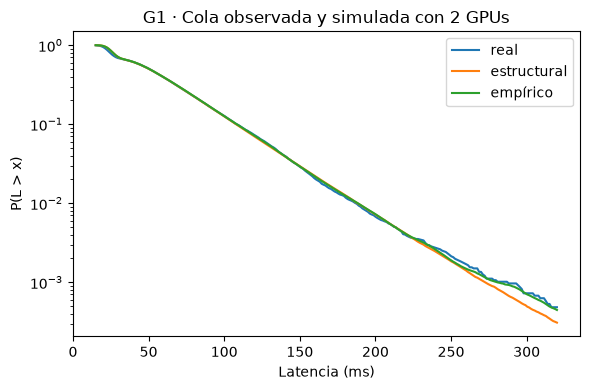

In [66]:
rep_g1 = 30
reales = est.latencia_ms.dropna().to_numpy()
mues_g = muestras_g(est)
g1 = {"real":reales}
for tipo in ("estructural","empírico"):
    g1[tipo] = np.concatenate([simular(2,param_g["lam"],param_g,1800,h,warmup=180,
                              muestras=mues_g if tipo=="empírico" else None) for h in rng.spawn(rep_g1)])
valid_g = pd.DataFrame({k:[*np.quantile(v,[.5,.9,.95,.99,.999]),np.mean(v>tau_grupo)]
                        for k,v in g1.items()},index=["p50","p90","p95","p99","p99.9","P(L>tau)"])
display(valid_g)
# Selección del modelo con menor error absoluto en la proporción de latencias sobre el umbral.
e_real = valid_g.loc["P(L>tau)","real"]
dist = {k:abs(valid_g.loc["P(L>tau)",k]-e_real) for k in ("estructural","empírico")}
modelo_g = min(dist,key=dist.get)
print("Modelo para proyección por error absoluto de cola G1:",modelo_g,dist)
fig,ax=plt.subplots(figsize=(6,4))
for k,v in g1.items():
    xx=np.linspace(15,320,250)
    ax.plot(xx,1-np.searchsorted(np.sort(v),xx,side="right")/len(v),label=k)
ax.set(xlabel="Latencia (ms)",ylabel="P(L > x)",yscale="log",title="G1 · Cola observada y simulada con 2 GPUs")
ax.legend()
fig.tight_layout()
fig.savefig(SALIDA/"figuraG1_validacion.png",dpi=150)
plt.show()


## G2 · Capacidad para la proyección del grupo

,rho,p,lo,hi,R
GPUs,,,,,
1,1.310756,NaN,NaN,NaN,0
2,0.655378,0.011944,0.011369,0.012519,40
3,0.436919,0.001268,0.001216,0.001320,40
4,0.327689,0.001048,0.001001,0.001096,40
5,0.262151,0.001022,0.000979,0.001066,40


c* por extremo superior: 2


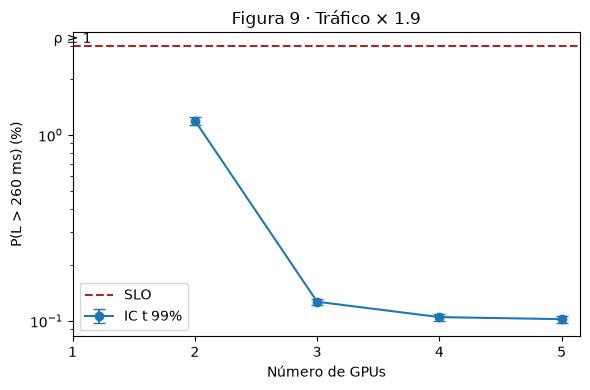

In [67]:
def replicar_g(c, p, muestras, cantidad, horizonte):
    tasa_proyectada = p["lam"] * g_grupo  # solicitudes por segundo
    marcas = muestras if modelo_g == "empírico" else None
    proporciones = []
    for rng_replica in rng.spawn(cantidad):
        latencias_ms = simular(
            c, tasa_proyectada, p, horizonte, rng_replica, warmup=180, muestras=marcas
        )
        # Se calcula la proporción de latencias que supera el umbral en ms.
        proporciones.append(np.mean(latencias_ms > tau_grupo))
    return np.asarray(proporciones)

candidatos_g = range(1,6)
filas_g = []
for c in candidatos_g:
    rho = g_grupo*param_g["lam"]*(1-param_g["h"])*EG/(1000*c)
    # Una carga de 1 o más deja a las GPUs sin margen para vaciar la cola en el modelo estacionario.
    if rho >= 1:
        filas_g.append((c,rho,np.nan,np.nan,np.nan,0))
        continue
    # Réplicas independientes y horizonte que deja 42 min útiles por réplica.
    pro = replicar_g(c,param_g,mues_g,40,2700)
    mg,lo_g,hi_g = ic_media(pro,conf_grupo)
    filas_g.append((c,rho,mg,max(0,lo_g),min(1,hi_g),len(pro)))
g2 = pd.DataFrame(filas_g,columns=["GPUs","rho","p","lo","hi","R"]).set_index("GPUs")
g2.to_csv(SALIDA/"G2_escenario_grupo.csv")
# Se selecciona el menor número de GPUs cuyo límite superior del intervalo cumple el SLO.
c_g = next(iter(g2.index[g2.hi.le(eps_grupo)]),None)
display(g2)
print("c* por extremo superior:",c_g)
fig,ax=plt.subplots(figsize=(6,4))
g2_ok=g2.dropna()
ax.errorbar(g2_ok.index,100*g2_ok.p,yerr=100*np.array([g2_ok.p-g2_ok.lo,g2_ok.hi-g2_ok.p]),
            fmt="o-",capsize=4,label=f"IC t {conf_grupo:.0%}")
ax.axhline(100*eps_grupo,color="firebrick",ls="--",label="SLO")
ax.set(xlabel="Número de GPUs",ylabel=f"P(L > {tau_grupo} ms) (%)",xticks=list(candidatos_g),
       title=f"Figura 9 · Tráfico × {g_grupo:.1f}")
for c in g2.index[g2.R.eq(0)]:
    ax.text(c,100*eps_grupo,"ρ ≥ 1",ha="center",va="bottom")
ax.set_yscale('log')
ax.legend()
fig.tight_layout()
fig.savefig(SALIDA/"figura9_c_vs_P.png",dpi=160)
plt.show()


## G3 · Incertidumbre paramétrica y referencia M/M/c

In [68]:
# Remuestreo por filas para ajustar marcas y por Poisson para estimar la tasa.
# c* bootstrap usa estimaciones puntuales condicionales. La dispersión incorpora error interior.
# Cada remuestra produce una nueva estimación de la capacidad mínima.
conteo_c = {}
diferencias_mc = []
for _ in range(100):
    muestra = est.iloc[rng.integers(0,len(est),len(est))]
    pb_g = ajustar(muestra,rng.poisson(len(est)))
    marcas_b = muestras_g(muestra)
    numero = None
    for c in candidatos_g:
        if g_grupo*pb_g["lam"]*(1-pb_g["h"])*pb_g["k"]*pb_g["theta"]/(1000*c)>=1:
            continue
        prop_b = replicar_g(c,pb_g,marcas_b,8,1800)
        if prop_b.mean()<=eps_grupo:
            numero = c
            break
    clave = str(numero) if numero is not None else ">5"
    conteo_c[clave]=conteo_c.get(clave,0)+1
print("Distribución de c* bootstrap (100 muestras):",conteo_c)

def mmc(c):
    mu=1000/EG
    lam_nc=g_grupo*param_g["lam"]*(1-param_g["h"])
    a=lam_nc/mu
    if a>=c:
        return np.nan
    cola=a**c/special.factorial(c)*c/(c-a)
    C=cola/(sum(a**k/special.factorial(k) for k in range(c))+cola)
    beta=c*mu-lam_nc
    tt=(tau_grupo-est.red_ms.mean())/1000
    suma=np.exp(-mu*tt)*(1+mu*tt) if abs(beta-mu)<1e-9 else (beta*np.exp(-mu*tt)-mu*np.exp(-beta*tt))/(beta-mu)
    return (1-param_g["h"])*((1-C)*np.exp(-mu*tt)+C*suma)
g2["p_MMc"]=[mmc(c) for c in g2.index]
display(g2)
print("M/M/c impone servicio exponencial y red constante. La cola empírica preserva la distribución observada de servicio, sin modelar cambios bajo saturación.")


Distribución de c* bootstrap (100 muestras): {'2': 100}


,rho,p,lo,hi,R,p_MMc
GPUs,,,,,,
1,1.310756,NaN,NaN,NaN,0,NaN
2,0.655378,0.011944,0.011369,0.012519,40,0.030970
3,0.436919,0.001268,0.001216,0.001320,40,0.005140
4,0.327689,0.001048,0.001001,0.001096,40,0.004249
5,0.262151,0.001022,0.000979,0.001066,40,0.004147


M/M/c impone servicio exponencial y red constante. La cola empírica preserva la distribución observada de servicio, sin modelar cambios bajo saturación.


## Resumen reproducible · A–G

In [69]:
def nativo(o):
    if isinstance(o,dict): return {str(k):nativo(v) for k,v in o.items()}
    if isinstance(o,(tuple,list)): return [nativo(v) for v in o]
    if isinstance(o,np.generic): return o.item()
    return o
resumen_final = dict(
    datos=[len(crudo),len(mon),len(df_val)],
    a=dict(limpios=len(est)+len(df_reg2),estable=len(est),cortes=[TAU1,TAU2],dur=dur_estable,
           tasas=[len(df[df.segmento==s])/(fin-a) for a,fin,s in SEGMENTOS],
           bic=modelos.BIC.tolist(),auditoria=tabla_A1["filas"].to_dict(),pearson_sens=comparacion_tam),
    b=dict(tasa=lambda_hat,ic=ic_lambda,pks=p_ks_b1,pdisp=p_dis_b1, bloques=tabla_b2.to_dict("records"),
           p=p_mle,ic_p=ic_p,k=k_val,prob=prob_analitica,mc=prob_mc),
    c=dict(h=h_hat,gpu=G_c.mean(),gamma=[k_mv,th_mv],media_mixta=G_todas.mean(),
           red=p999_emp,ic_red=[orden[l-1],orden[min(u,n_red)-1]],c4=res_N,ks=p_ks_gam),
    d=dict(pearson=r_xy,ic=[r_lo,r_hi],pendiente=beta[1],pendiente_hc3=[beta[1]-stats.t.ppf(1-alpha/2,n3-2)*ee_hc3[1],beta[1]+stats.t.ppf(1-alpha/2,n3-2)*ee_hc3[1]],explicada=tabla_D2.iloc[0]["fracción explicada"],v=V,p=p_ind_tam),
    e=dict(regla=recomendada,prob=e4.loc[recomendada,"P(X<=kmax) puntual"],peor=e4.loc[recomendada,"P(X<=kmax) peor caso"],
           sensibilidad=e1.loc[recomendada,"sens"],cumple=bool(e4.cumple.any()),max=kmax),
    f=dict(diferencias=f3,latencia=[m_bm,lo_bm,hi_bm],n_f5=n_req,n_tlc=n_min,validacion=f6_cambios,disp_validacion=p_disp_val),
    g=dict(c=c_g,crecimiento=g_grupo,tau=tau_grupo,eps=eps_grupo,conf=conf_grupo,
           modelo=modelo_g,validacion=valid_g.to_dict(),tabla=g2.replace({np.nan:None}).to_dict("index"),bootstrap=conteo_c))
resumen_final = nativo(resumen_final)
Path("resumen_consolidado.json").write_text(json.dumps(resumen_final,ensure_ascii=False,indent=2,allow_nan=False),encoding="utf8")
display(pd.DataFrame(g2))


,rho,p,lo,hi,R,p_MMc
GPUs,,,,,,
1,1.310756,NaN,NaN,NaN,0,NaN
2,0.655378,0.011944,0.011369,0.012519,40,0.030970
3,0.436919,0.001268,0.001216,0.001320,40,0.005140
4,0.327689,0.001048,0.001001,0.001096,40,0.004249
5,0.262151,0.001022,0.000979,0.001066,40,0.004147
